# TP 1: From raw text to a first bigram model

I build a language model that reads one character and predicts the next from a table of scores. This is the starting point of my mini-Transformer.

My main question is how to distinguish insufficient training from the limits of seeing only one character. A poor sample could come from either cause. I need measurements that help me decide what to try next.

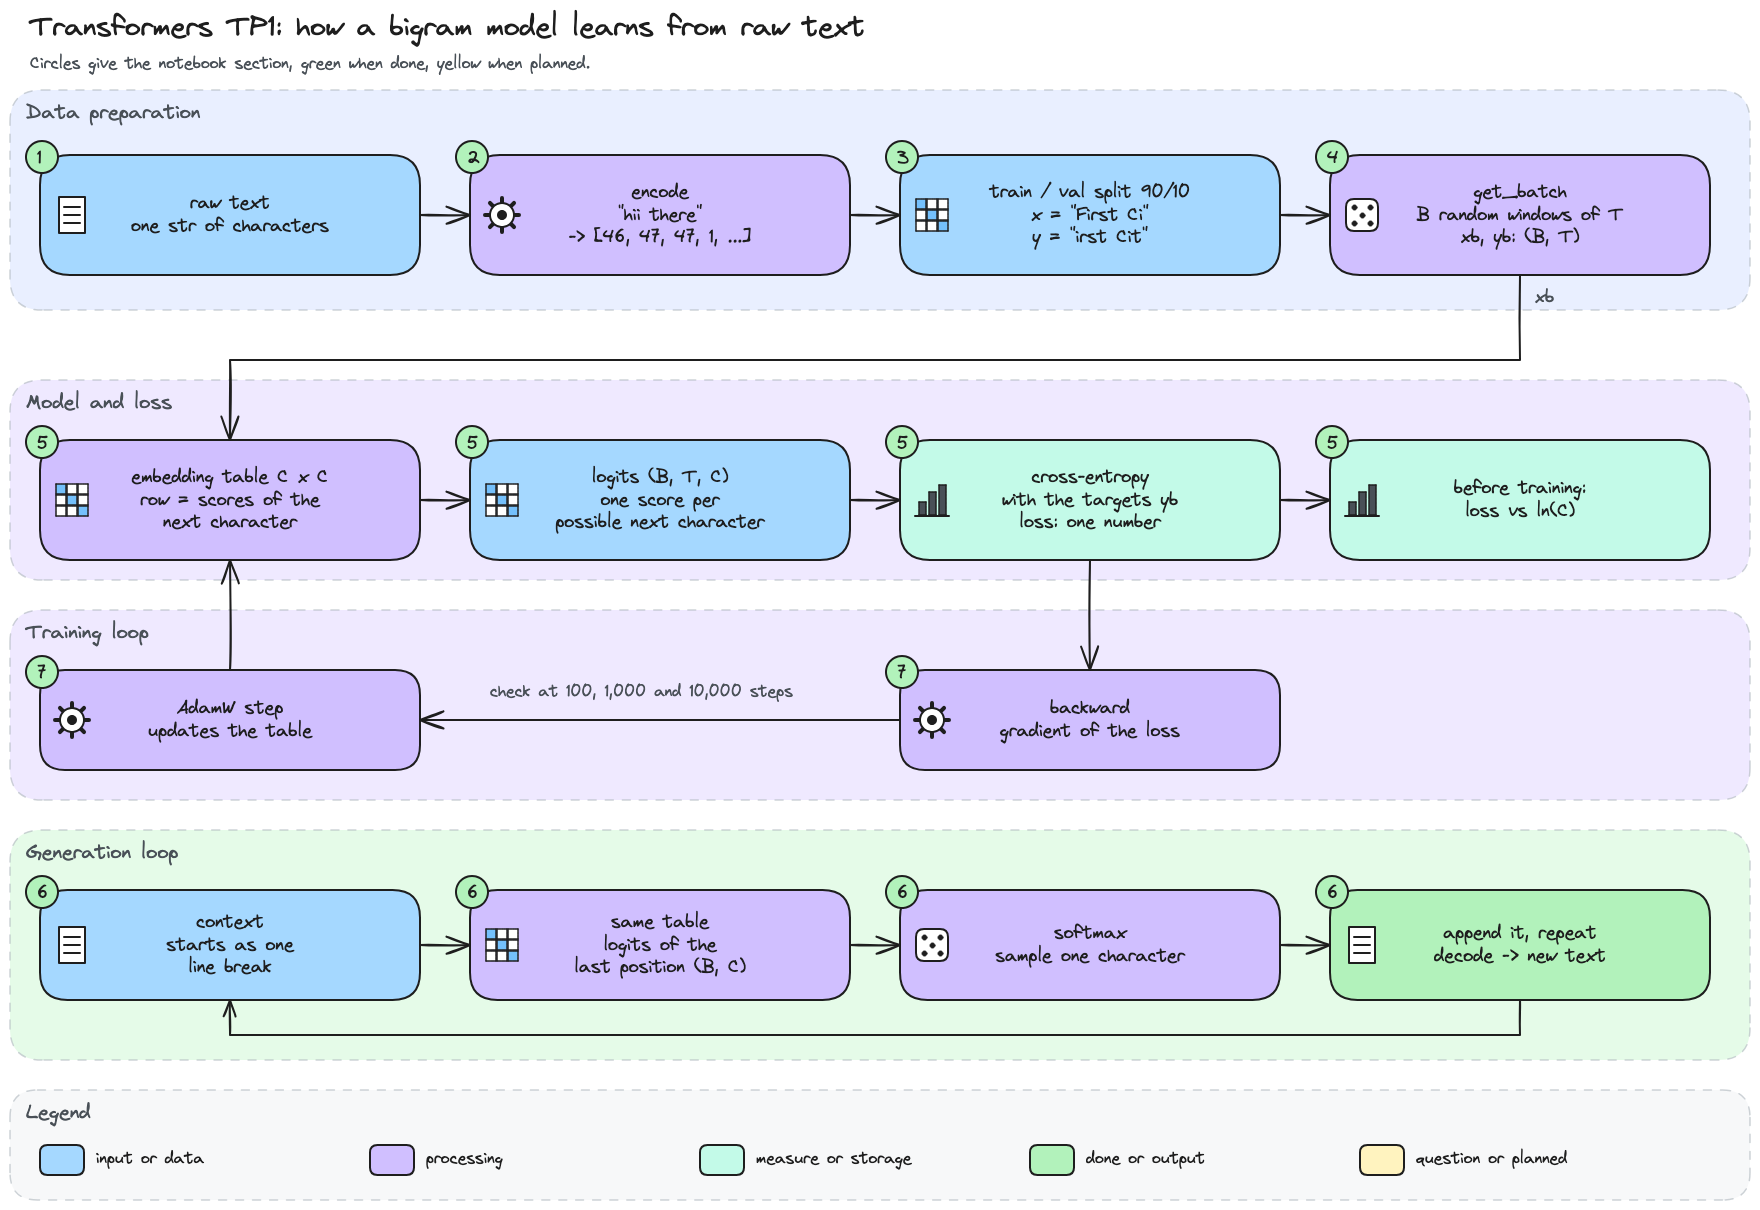

In [1]:
# Workflow diagram: one example through data, model, loss and both loops (diagrams/transformers/).
from IPython.display import Image, display

display(Image(filename='diagrams/transformers/tp1_workflow.png', width=900))

## 0. My problem and what I carry over

In my earlier NLP work, I used Tiny Shakespeare to identify speakers from their replies. Here, the text supplies its own targets because each character is followed by the answer I want to predict.

I keep the raw text because punctuation, capitals and line breaks are now part of the output. I will inspect these patterns before deciding what a successful bigram should reproduce.

I use a counted bigram as a reference for what this model family can learn. Comparing it with the trained table should help separate an optimisation problem from a missing-context problem.

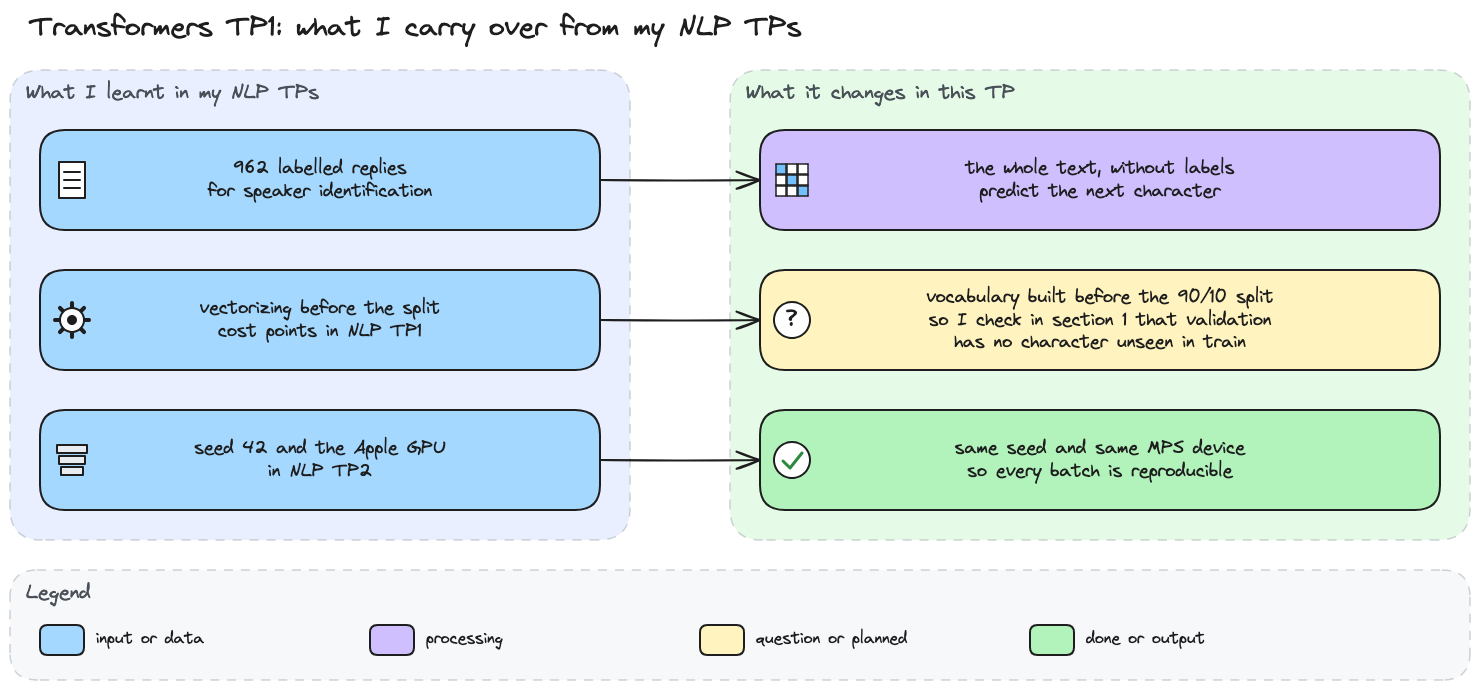

In [2]:
# What I carry over from my NLP TPs (source in diagrams/transformers/).
display(Image(filename='diagrams/transformers/tp1_carry_over.png', width=900))

Before I start, I write down what I expect, so I can check it later.

> *My hypotheses:*
>
> - The corpus has fewer than 100 distinct characters, since it is English text with some punctuation. Sections 1 and 2 check it.
> - Before training, the loss is close to ln(C), where C is the number of distinct characters, because random weights give an almost uniform distribution. I test it in section 5.
> - With a learning rate of 1e-3 (the scale of each weight update), 100 steps barely lower the loss and 1,000 steps lower it clearly. Section 7 compares both.
> - After training, samples keep the line breaks and the capitalised speaker names but contain few real words, because the model only sees the previous character. Section 7 tests this too.

### My environment

I use the project's `.venv/bin/python` as kernel and install the dependencies from the terminal.

```sh
uv pip install --python .venv/bin/python -r requirements.txt
```

I use PyTorch to inspect the forward pass, loss and weight update separately. The notebook uses MPS, the PyTorch backend for Apple GPUs, when available. Dependency versions are pinned in `requirements.txt`.

I fix seed 42 to make comparisons reproducible in this environment. One seed gives me a controlled example, but it does not measure how much the results vary between runs.

In [3]:
# Environment: versions, hardware, PyTorch device and one seed for random and torch.
import platform
import random
import subprocess
import sys
from importlib.metadata import version

import torch

# Seed fixed once here, so every random draw below is reproducible.
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Apple GPU through MPS when available, CPU otherwise
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')

# Versions and dependencies
print(f'Python: {platform.python_version()} ({sys.executable})')
for package in ('torch', 'numpy', 'matplotlib', 'ipykernel'):
    print(f'{package}: {version(package)}')

# System and processor
print(f'System: {platform.platform()}, {platform.machine()}')
if sys.platform == 'darwin':
    processor, ram = subprocess.check_output(
        ['sysctl', '-n', 'machdep.cpu.brand_string', 'hw.memsize'], text=True,
    ).splitlines()
    print(f'Processor: {processor}, RAM: {int(ram) / 2**30:g} GiB')

print(f'Device: {device}, seed: {RANDOM_STATE}')

Python: 3.14.7 (/Users/hopy/Documents/ING3_GIA/ING3_IA_GB_S1/NLP/.venv/bin/python)
torch: 2.14.0
numpy: 2.5.3
matplotlib: 3.11.1
ipykernel: 7.3.0
System: macOS-26.5-arm64-arm-64bit-Mach-O, arm64
Processor: Apple M3 Max, RAM: 36 GiB
Device: mps, seed: 42


## 1. Download and inspect the corpus

I first inspect what the model will read and what I will ask it to generate. Character frequencies give me simple reference predictions. Pairs of neighbours then show how much information one preceding character provides.

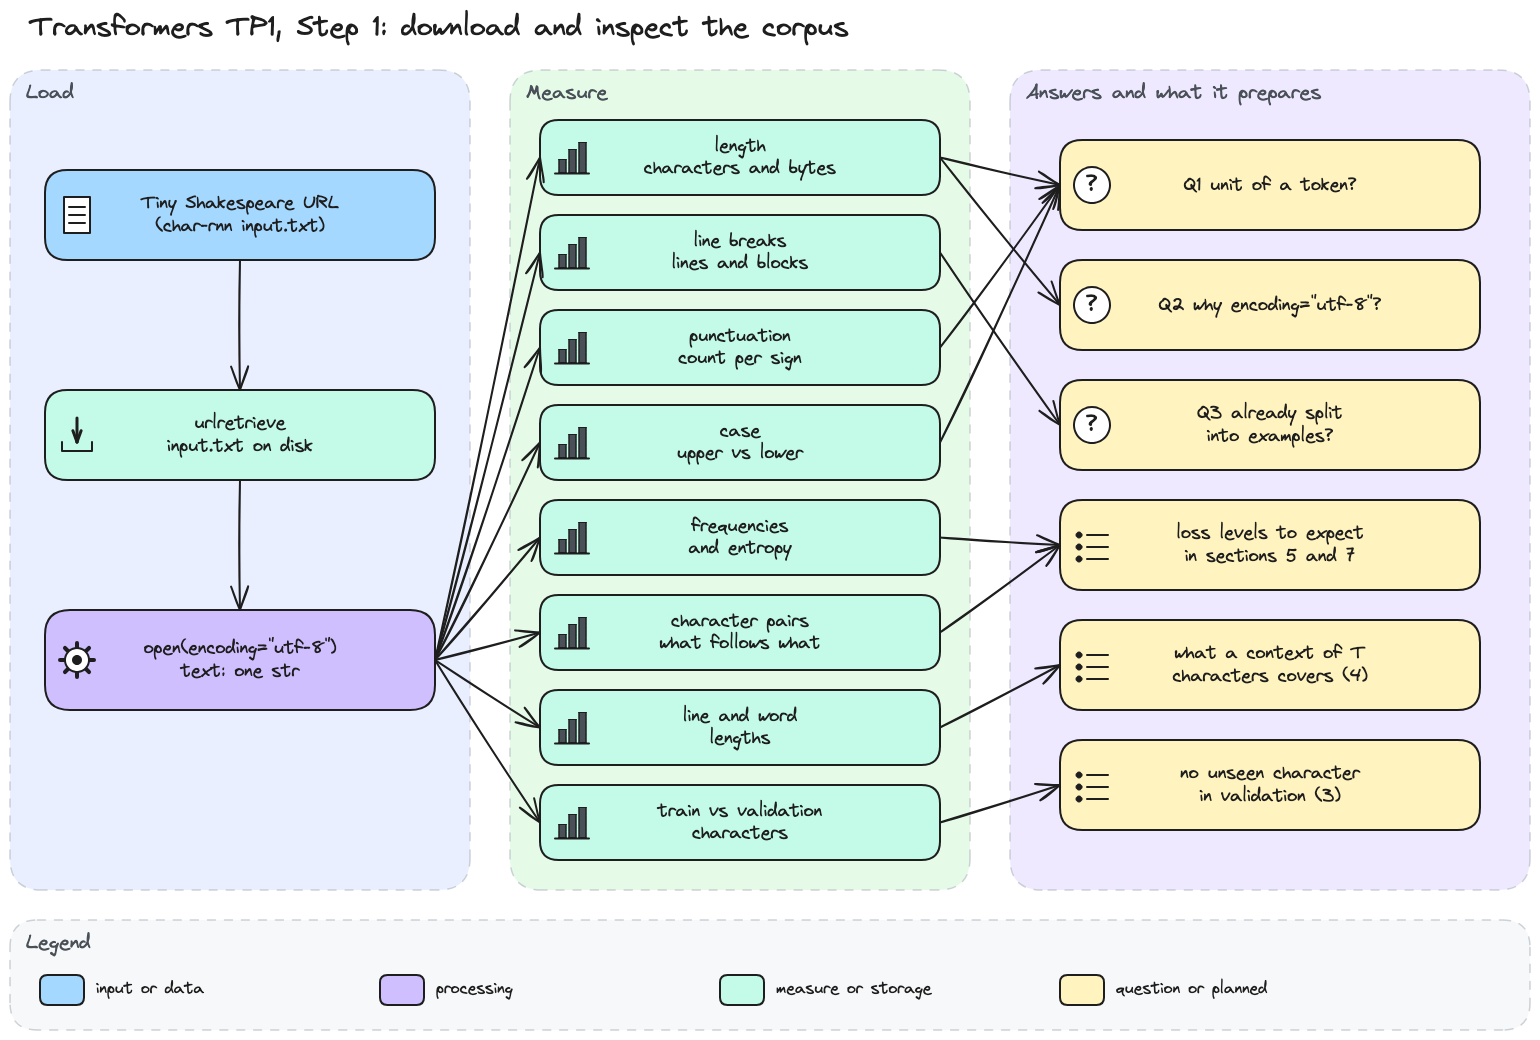

In [4]:
# Step 1 diagram: from the URL to the measures that answer my three questions.
display(Image(filename='diagrams/transformers/tp1_step1.png', width=900))

I read the corpus into one string called `text` so that I can inspect its original order before constructing examples.

In [5]:
# Download Tiny Shakespeare and read it as one string.
from urllib.request import urlretrieve
import os

url = ("https://raw.githubusercontent.com/karpathy/"
       "char-rnn/master/data/tinyshakespeare/input.txt")
urlretrieve(url, "input.txt")
print(os.path.abspath("input.txt"))

with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

print(len(text))

/Users/hopy/Documents/ING3_GIA/ING3_IA_GB_S1/NLP/input.txt
1115394


The whole corpus is one Python string of 1,115,394 characters. Nothing is cut into sentences or examples yet, so everything the model learns will come from this single sequence. I print its beginning to see how it is organised.

In [6]:
# The first 1,000 characters, exactly as the model will read them.
print(text[:1000])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in thirst for revenge.



The text is a play script. A speaker name sits alone on a line and ends with a colon, the reply follows on the next lines, and an empty line closes the block. Punctuation and capitals stay as written, as in `Resolved. resolved.` or `We know't, we know't.`, so the model will have to produce them too.

I opened the file with `encoding="utf-8"`, and I want to know whether this choice changes anything for this file.

In [7]:
# Does the encoding matter here? Compare characters with bytes and look for non-ASCII characters.
import locale

print(f'Characters: {len(text):,}, bytes on disk: {os.path.getsize("input.txt"):,}')
print(f'Non-ASCII characters: {sum(not char.isascii() for char in text)}')
print(f'Default encoding of open() on this machine: {locale.getpreferredencoding(False)}')

Characters: 1,115,394, bytes on disk: 1,115,394
Non-ASCII characters: 0
Default encoding of open() on this machine: UTF-8


The file contains only ASCII characters, with one byte per character. UTF-8 therefore reads every character in this file without ambiguity.

I specify `encoding="utf-8"` so that reading the file does not depend on the machine's default encoding. This protects the reading step without changing the text.

The empty lines suggest blocks of dialogue. I next check whether those blocks already provide the inputs and targets a model needs.

In [8]:
# Is the text already cut into examples? Count lines, blocks and blocks opened by a speaker name.
import re

line_breaks = text.count('\n')
blocks = text.split('\n\n')
first_lines = [block.split('\n', 1)[0] for block in blocks]
headers = [line for line in first_lines if re.fullmatch(r"[A-Z][A-Za-z' ]*:", line)]  # "Name:"

print(f'Line breaks: {line_breaks:,}')
print(f'Blocks separated by an empty line: {len(blocks):,}')
print(f'Blocks opened by a speaker name alone on its line: {len(headers):,}')

Line breaks: 40,000
Blocks separated by an empty line: 7,222
Blocks opened by a speaker name alone on its line: 7,217


I count 40,000 line breaks and 7,222 blocks separated by empty lines. Of these blocks, 7,217 begin with a speaker name. These are useful clues about the script's layout.

A dialogue block is not yet a training example because I have not defined what the model receives or predicts. I will create those pairs by shifting the character sequence in section 3.

I now group characters by kind to see how often the model will encounter letters, spaces and punctuation.

In [9]:
# Tools: a percentage helper, character category and display, and a bar chart with values.
import string

import matplotlib.pyplot as plt


def percentage(part: int, total: int) -> float:
    """Share of part in total, in percent, rounded to two decimals."""
    return round(100 * part / total, 2)


def character_category(char: str) -> str:
    """Category of one character: line break, space, letter case, digit or punctuation."""
    if char == '\n':
        return 'line break'
    if char == ' ':
        return 'space'
    if char.islower():
        return 'lowercase letter'
    if char.isupper():
        return 'uppercase letter'
    if char.isdigit():
        return 'digit'
    return 'punctuation' if char in string.punctuation else 'other'


def shown(char: str) -> str:
    """Printable form of a character: the line break as \\n and the space as ␣."""
    return {'\n': '\\n', ' ': '␣'}.get(char, char)


def tick(char: str) -> str:
    """Label of a character on a chart, with "$" escaped so it is not read as a formula."""
    return shown(char).replace('$', r'\$')


def bar_chart(labels: list[str], values: list[int], notes: list[str], title: str) -> None:
    """Horizontal bar chart with a note written at the end of each bar."""
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(labels) + 1))
    bars = ax.barh(labels, values, color='#74c0fc')
    ax.bar_label(bars, labels=notes, padding=4)
    ax.set_xlim(0, max(values) * 1.7)
    ax.xaxis.set_major_formatter('{x:,.0f}')
    ax.set_xlabel('occurrences in the text')
    ax.set_title(title)
    ax.spines[['top', 'right']].set_visible(False)
    plt.show()

Distinct characters: 65


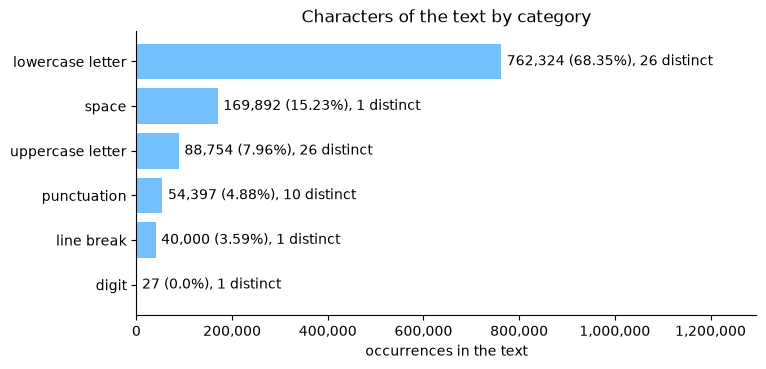

In [10]:
# What kind of characters will the model have to predict?
from collections import Counter

counts = Counter(text)
occurrences, distinct = Counter(), Counter()
for char, n in counts.items():
    occurrences[character_category(char)] += n
    distinct[character_category(char)] += 1

print(f'Distinct characters: {len(counts)}')
categories = sorted(occurrences, key=occurrences.get)
bar_chart(categories, [occurrences[c] for c in categories],
          [f'{occurrences[c]:,} ({percentage(occurrences[c], len(text))}%), '
           f'{distinct[c]} distinct' for c in categories],
          'Characters of the text by category')

I use one character as one token, including spaces and line breaks. The 65 distinct characters support my initial expectation of fewer than 100 tokens.

Lowercase letters account for 68.35% of the text and spaces for 15.23%. These frequencies matter because a loss averaged over all positions gives common characters more influence than rare ones.

Uppercase and lowercase letters remain separate tokens. Punctuation occupies only 4.88% of positions but includes 10 signs, so I inspect it before treating rare errors as unimportant.

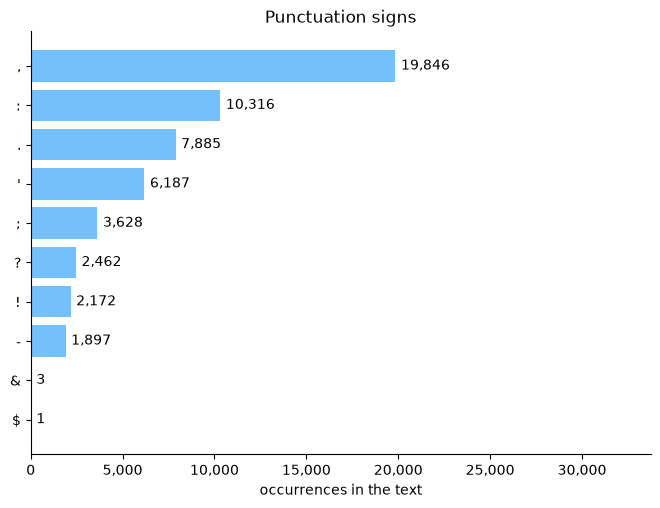

In [11]:
# Which punctuation signs appear, and how often?
signs = sorted((c for c in counts if character_category(c) == 'punctuation'), key=counts.get)
bar_chart([tick(sign) for sign in signs], [counts[sign] for sign in signs],
          [f'{counts[sign]:,}' for sign in signs], 'Punctuation signs')

The comma appears 19,846 times and the colon 10,316 times. Of those colons, 7,217 close a speaker name, so predicting punctuation also helps reproduce the script's layout.

The signs `&` and `$` appear only 3 times and once. I expect estimates for these characters to be fragile because training receives so few examples of them.

I next check whether capitals also carry information about the layout.

In [12]:
# Where do the capitals come from? Count the capitals that belong to speaker names.
capitals = sum(char.isupper() for char in text)
capitals_in_names = sum(char.isupper() for header in headers for char in header)

print(f'Capitals: {capitals:,}, in speaker names: {capitals_in_names:,} '
      f'({percentage(capitals_in_names, capitals)}%)')
print(f'Speaker names: {len(headers):,}')

Capitals: 88,754, in speaker names: 54,795 (61.74%)
Speaker names: 7,217


Speaker names account for 61.74% of the capitals. The 54,795 capitals across 7,217 names give about 7.6 capitals per name, although `First Citizen` shows that names are not always fully capitalised.

This gives me a concrete feature to inspect in generated text. I can look for capital sequences and name-like lines, while remembering that a bigram cannot recognise an entire speaker name.

Before using loss to judge these predictions, I need to make its scale understandable.

For one prediction, I look at the probability assigned to the character that actually follows. The loss is its negative natural logarithm, `-log(p)`. A confident correct prediction receives a smaller penalty.

I first calculate three illustrative penalties. These probabilities are chosen examples, not measurements of the corpus.

In [13]:
# Relate the probability of a correct character to its loss, then average three penalties.
import math

demo_probabilities = (0.5, 0.1, 0.01)
demo_penalties = [-math.log(p) for p in demo_probabilities]
for demo_p, demo_penalty in zip(demo_probabilities, demo_penalties):
    print(f'Correct-character probability {demo_p:g}: loss {demo_penalty:.3f} nats')
print(f'Mean loss across these three predictions: {sum(demo_penalties) / 3:.3f} nats')
assert demo_penalties[0] < demo_penalties[1] < demo_penalties[2]
assert math.isclose(-math.log(1.0), 0.0)

Correct-character probability 0.5: loss 0.693 nats
Correct-character probability 0.1: loss 2.303 nats
Correct-character probability 0.01: loss 4.605 nats
Mean loss across these three predictions: 2.534 nats


A correct-character probability of 0.5 costs 0.693 nats. Lowering it to 0.1 costs 2.303, and 0.01 costs 4.605. The model is penalised more strongly when it gives the observed answer very little probability.

The mean is 2.534 nats for these three predictions. Cross-entropy averages the penalties at the evaluated positions. A nat is the unit obtained with the natural logarithm, so this loss is not a percentage of wrong answers.

I can now calculate reference losses for the corpus and interpret what their differences mean.

Uniform guess, ln(65): 4.17 nats
Guess by frequency, entropy of the shares: 3.31 nats


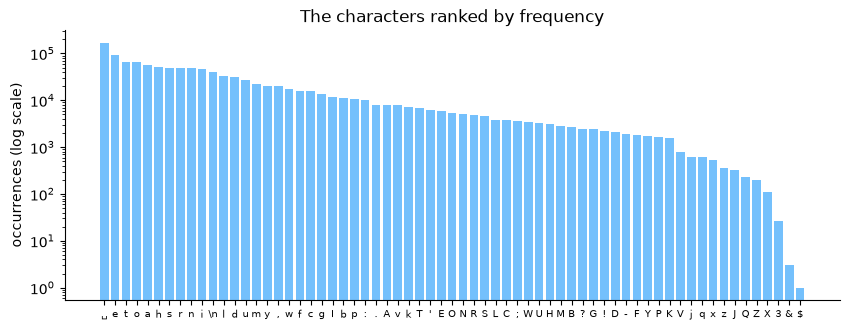

In [14]:
# How often does each character appear, and what does a guess without context cost?
import math

ranked = counts.most_common()
shares = [n / len(text) for _, n in ranked]
entropy = -sum(p * math.log(p) for p in shares)
print(f'Uniform guess, ln({len(counts)}): {math.log(len(counts)):.2f} nats')
print(f'Guess by frequency, entropy of the shares: {entropy:.2f} nats')

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(range(len(ranked)), [n for _, n in ranked], color='#74c0fc')
ax.set_yscale('log')
ax.set_xticks(range(len(ranked)), [tick(char) for char, _ in ranked], fontsize=7)
ax.set_ylabel('occurrences (log scale)')
ax.set_title('The characters ranked by frequency')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The space is the most frequent character, while `$` occurs once. A model that always assigns the same distribution can exploit these unequal frequencies without using any context.

Giving each of the 65 characters equal probability costs 4.17 nats per prediction. Using the measured character frequencies lowers the average to 3.31. I can therefore improve on uniform guessing before learning any relationship between characters.

These frequencies describe the whole corpus. I use them here to understand its difficulty, not as a model fitted only on the training split.

My initial hypothesis assumes that random weights behave almost like equal scores. I keep that assumption visible so that section 5 can test it. First, I measure what changes when a prediction uses the preceding character.

In [15]:
# Which character follows which? Count every pair of neighbours, then normalise each row.
import numpy as np

alphabet = sorted(counts)
index = {char: i for i, char in enumerate(alphabet)}
pair_counts = np.zeros((len(alphabet), len(alphabet)))
for (current, following), n in Counter(zip(text, text[1:])).items():
    pair_counts[index[current], index[following]] = n
next_probs = pair_counts / pair_counts.sum(axis=1, keepdims=True)

# Best loss of a bigram table: the mean of -ln P(next | current) over every pair of the text
seen = pair_counts > 0
bigram_loss = -(pair_counts[seen] * np.log(next_probs[seen])).sum() / pair_counts.sum()
print(f'Pairs that occur: {seen.sum():,} of {len(alphabet) ** 2:,}')
print(f'Best loss of a bigram table on this text: {bigram_loss:.2f} nats')
for char in ('\n', ':', 'q'):
    row = next_probs[index[char]]
    top = [j for j in np.argsort(row)[::-1][:3] if row[j] > 0]
    followers = ', '.join(f'"{shown(alphabet[j])}" {100 * row[j]:.1f}%' for j in top)
    print(f'After "{shown(char)}": {followers}')

Pairs that occur: 1,403 of 4,225
Best loss of a bigram table on this text: 2.45 nats
After "\n": "\n" 18.1%, "T" 10.4%, "A" 9.6%
After ":": "\n" 84.9%, "␣" 14.7%, "'" 0.2%
After "q": "u" 100.0%


I observe 1,403 of the 4,225 possible character pairs. After `q`, the next character is always `u` in this corpus. After `:`, a line break follows 84.9% of the time.

These examples explain why knowing the current character can help. It narrows the plausible next characters, although the uncertainty depends on the row of the table.

After a line break, another line break is the most common follower at 18.1%, followed by `T` and `A`. This suggests that local transitions can reproduce some layout without recognising a scene or speaker.

The empirical conditional entropy is 2.45 nats on the whole corpus. It is the lowest average loss attainable by unrestricted bigram probabilities fitted to these same pairs. Section 3 will build a separate reference using training counts only.

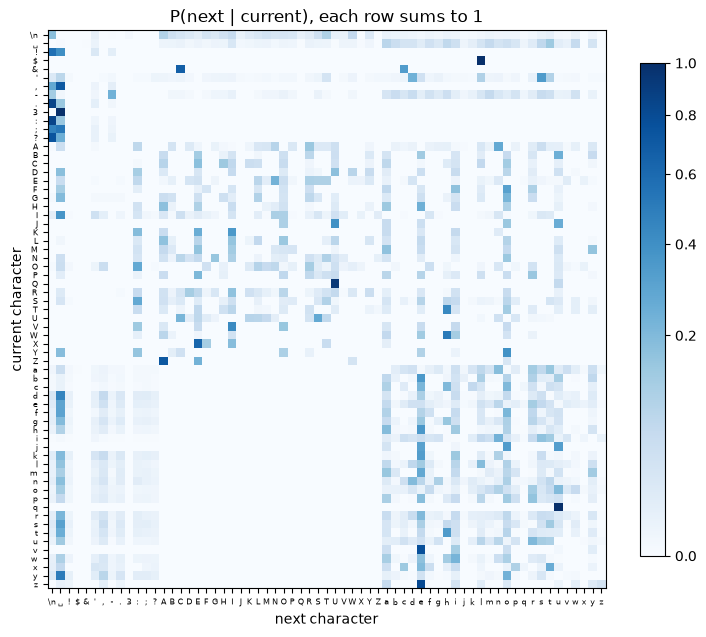

In [16]:
# The same table as a picture: one row per current character, one column per next character.
from matplotlib.colors import PowerNorm

labels = [tick(char) for char in alphabet]
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(next_probs, cmap='Blues', norm=PowerNorm(0.5))  # square root shows faint cells
ax.set_xticks(range(len(alphabet)), labels, fontsize=6)
ax.set_yticks(range(len(alphabet)), labels, fontsize=6)
ax.set_xlabel('next character')
ax.set_ylabel('current character')
ax.set_title('P(next | current), each row sums to 1')
fig.colorbar(image, ax=ax, shrink=0.8)
plt.show()

Each row describes what follows one character. The dense lowercase block means that letters often lead to other lowercase letters, spaces or punctuation. Capitals also lead to capitals inside names and to lowercase letters inside words.

The white cells correspond to unobserved transitions. I should not interpret them as impossible in every other text. This distinction will matter when I score validation pairs missing from training.

The table uses one preceding character. I next examine line and word lengths to understand what a longer context could contain.

Lines: 32,777, median 39 characters, longest 63
Words: 204,062, median 4 characters


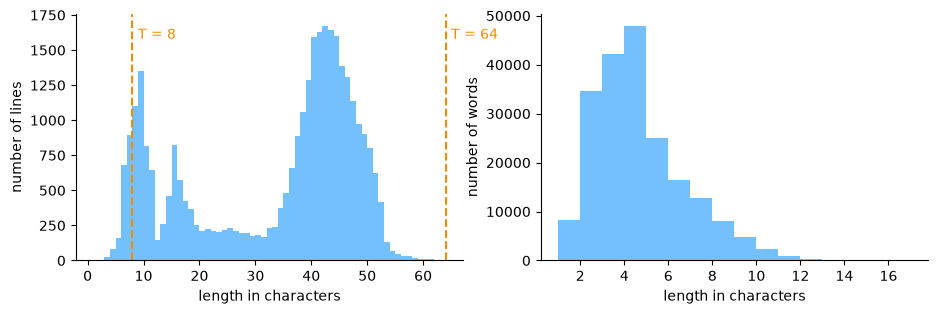

In [17]:
# How long are lines and words? This tells me what a context of T characters can see.
import statistics

line_lengths = [len(line) for line in text.split('\n') if line]
word_lengths = [len(word) for word in re.findall(r"[A-Za-z']+", text)]  # letters, apostrophes
print(f'Lines: {len(line_lengths):,}, median {statistics.median(line_lengths):g} characters, '
      f'longest {max(line_lengths)}')
print(f'Words: {len(word_lengths):,}, median {statistics.median(word_lengths):g} characters')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, lengths, name in ((axes[0], line_lengths, 'lines'), (axes[1], word_lengths, 'words')):
    ax.hist(lengths, bins=range(1, max(lengths) + 2), color='#74c0fc')
    ax.set_xlabel('length in characters')
    ax.set_ylabel(f'number of {name}')
    ax.spines[['top', 'right']].set_visible(False)
for t in (8, 64):
    axes[0].axvline(t, color='#f08c00', linestyle='--')
    axes[0].text(t + 1, axes[0].get_ylim()[1] * 0.9, f'T = {t}', color='#f08c00')
plt.show()

Line lengths cluster around short name-like lines and longer verse lines. The median is 39 characters and the longest line has 63. Words have a median length of 4 characters.

A window of T = 8 can cover a short word and part of its surroundings. T = 64 can cross a line boundary. These lengths describe available input, but the bigram still reads each position without its earlier context.

That difference prevents me from crediting a larger T with more context understanding in this model. I next check whether the planned validation split contains characters absent from training.

Characters only in validation: 0 []
Characters only in train: 4 ['$', '&', '3', 'X']
Largest rises in validation: O x1.82, Z x2.07, P x3.31
Largest drops in validation: Q x0.04, J x0.23, Y x0.38


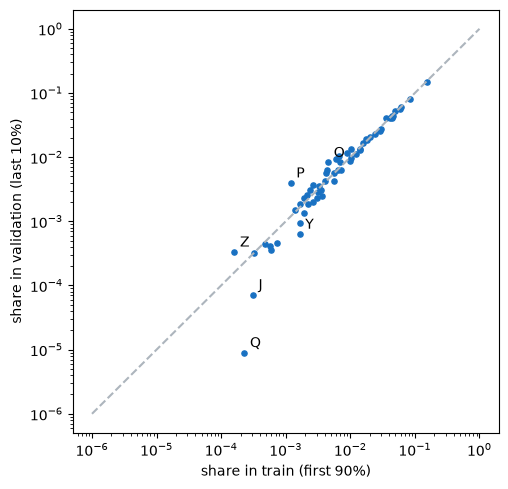

In [18]:
# Does the last 10% of the text, my future validation set, use the same characters as the rest?
split_at = int(0.9 * len(text))
train_counts, val_counts = Counter(text[:split_at]), Counter(text[split_at:])
only_val = sorted(set(val_counts) - set(train_counts))
only_train = [shown(char) for char in sorted(set(train_counts) - set(val_counts))]
print(f'Characters only in validation: {len(only_val)} {only_val}')
print(f'Characters only in train: {len(only_train)} {only_train}')

# Share of each common character in both parts, and the ones whose share moves most
common = [char for char in alphabet if char in val_counts]
train_share = {char: train_counts[char] / split_at for char in common}
val_share = {char: val_counts[char] / (len(text) - split_at) for char in common}
by_ratio = sorted(common, key=lambda char: val_share[char] / train_share[char])
rises = ', '.join(f'{shown(c)} x{val_share[c] / train_share[c]:.2f}' for c in by_ratio[-3:])
drops = ', '.join(f'{shown(c)} x{val_share[c] / train_share[c]:.2f}' for c in by_ratio[:3])
print(f'Largest rises in validation: {rises}')
print(f'Largest drops in validation: {drops}')

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(train_share.values(), val_share.values(), s=14, color='#1971c2')
ax.plot([1e-6, 1], [1e-6, 1], linestyle='--', color='#adb5bd')  # same share in both parts
for char in by_ratio[:3] + by_ratio[-3:]:
    ax.annotate(shown(char), (train_share[char], val_share[char]), xytext=(4, 4),
                textcoords='offset points')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('share in train (first 90%)')
ax.set_ylabel('share in validation (last 10%)')
plt.show()

Every validation character also appears in training. Building this closed vocabulary from the whole file therefore introduces no additional character from validation. It still gives no guarantee about unseen characters in another corpus.

The characters `$`, `&`, `3` and `X` appear only in training, so validation will not assess their predictions. Most shared characters have similar frequencies, but some capitals change considerably.

`P` is 3.31 times more frequent in validation and `Z` 2.07 times, while `Q` falls to 0.04 times its training share. Different speaker names could explain this. I will inspect the speakers around the split in section 3 before treating that explanation as established.

> *My conclusion:*
>
> I keep case, punctuation and line breaks because they are features of the text I want to generate. The corpus contains useful regularities at both the character and pair levels.
>
> The whole-corpus references are 4.17 nats for uniform guessing, 3.31 for character frequencies and 2.45 for fitted bigram probabilities. They give the loss a scale. I still need a training-only reference for validation.
>
> My answers to the three questions of this step:
>
> 1. One token is one character, and the vocabulary contains 65 characters.
> 2. Explicit UTF-8 decoding avoids depending on the machine's default encoding.
> 3. The file is one string. Its 7,222 dialogue blocks become supervised examples only after I define contexts and next-character targets.

## 2. Map characters to integers

The model needs an address for each character so that it can select a row of its table. I build a stable mapping, then check that converting text to ids and back preserves the input.

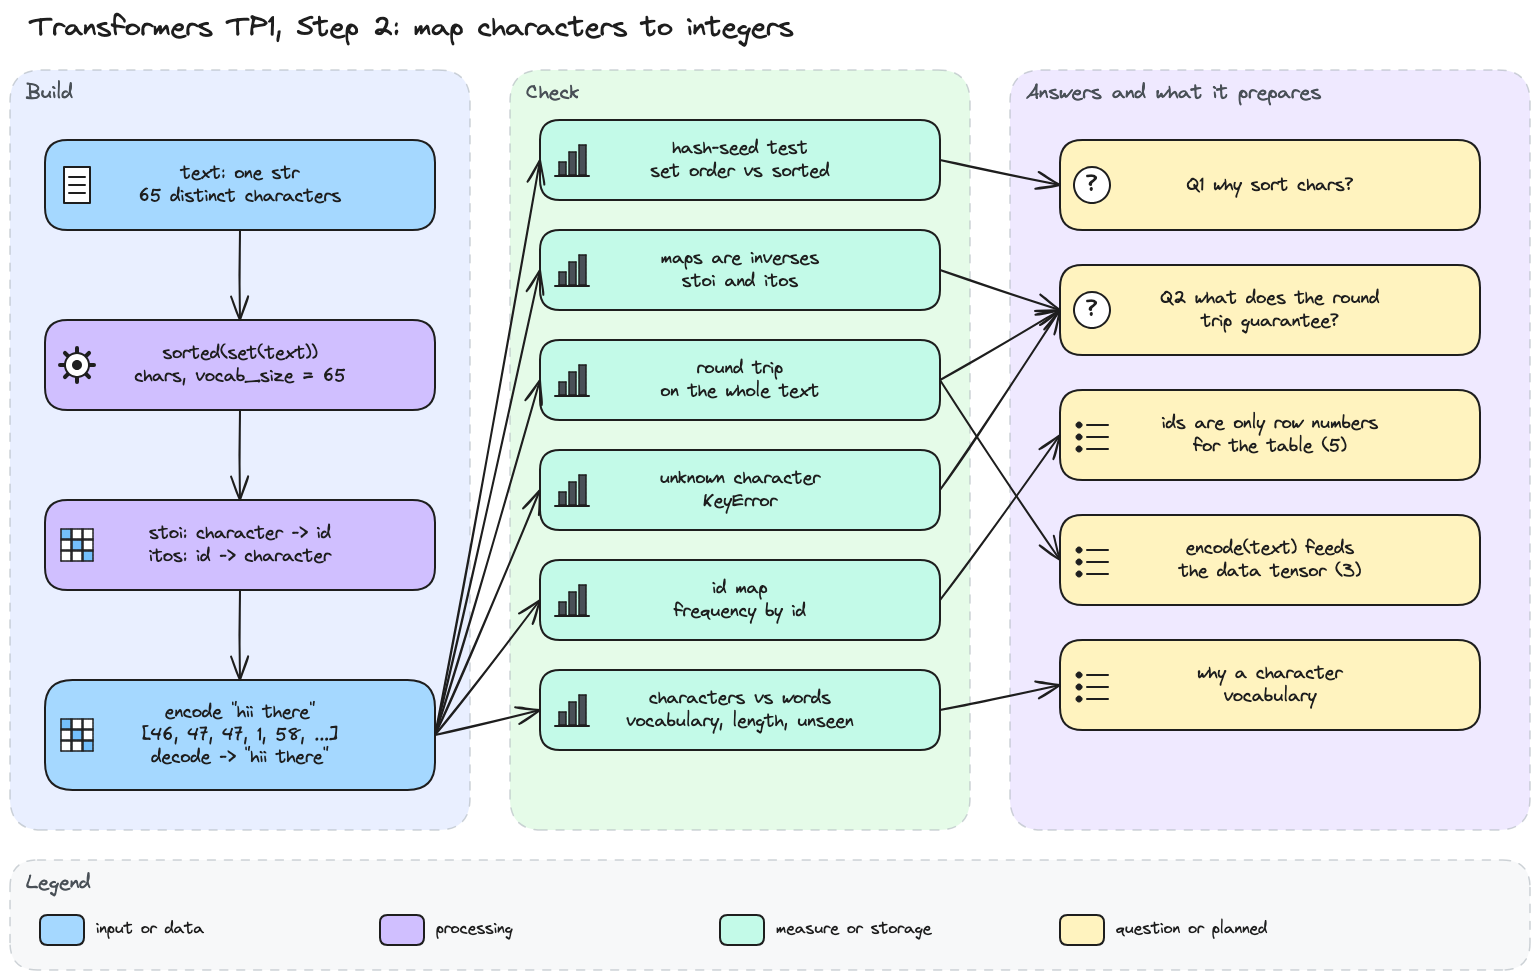

In [19]:
# Step 2 diagram: vocabulary, maps, encode and decode, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp1_step2.png', width=900))

In [20]:
# Vocabulary: the distinct characters of the text, sorted and numbered, then the two maps.
chars = sorted(list(set(text)))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

print(f'vocab_size: {vocab_size}')
print(f'Vocabulary in id order: {"".join(shown(ch) for ch in chars)}')
print(f'itos undoes stoi: {all(itos[stoi[ch]] == ch for ch in chars)}')
print(f'stoi undoes itos: {all(stoi[itos[i]] == i for i in range(vocab_size))}')

vocab_size: 65
Vocabulary in id order: \n␣!$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
itos undoes stoi: True
stoi undoes itos: True


The vocabulary has 65 characters, so my hypothesis of fewer than 100 distinct characters is confirmed. Both checks print True, so every character has exactly one id and every id exactly one character. In id order, the line break comes first, then the space, the signs and the digit, the capitals and the lowercase letters. That is the order of the character codes, because `sorted` compares characters by their code.

A set has no order of its own, though. I want to see what would happen if I numbered the characters straight from the set.

In [21]:
# Why sort? Build the vocabulary in three new Python processes, each with another hash seed.
import os
import subprocess
import sys

SNIPPET = ("text = open('input.txt', encoding='utf-8').read()\n"
           "print('set', repr(''.join(list(set(text)))[:12]),"
           " ' sorted', repr(''.join(sorted(set(text)))[:12]))")

for seed in ('1', '2', '3'):
    child = subprocess.run([sys.executable, '-c', SNIPPET], capture_output=True, text=True,
                           env={**os.environ, 'PYTHONHASHSEED': seed})
    print(f'hash seed {seed}: {child.stdout.strip()}')

hash seed 1: set 'VtM.;k3b$LyR'  sorted "\n !$&',-.3:;"
hash seed 2: set 'hkIJEmO:VG&p'  sorted "\n !$&',-.3:;"
hash seed 3: set 'JayQo:fDk?u!'  sorted "\n !$&',-.3:;"


The set produces different orders across the three processes, while sorting gives the same order. String hashing affects set iteration, so I cannot use that order as a stable numbering scheme.

I sort `chars` so that rebuilding the vocabulary from the same characters preserves each row's meaning. Reloading weights with a different mapping would decode their predictions incorrectly. Saving the mapping alongside weights would also protect that correspondence.

I can now test `encode` and `decode` on a short message.

In [22]:
# Encode and decode as two lambdas, tried on a short message.
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: ''.join([itos[i] for i in ids])

message = "hii there"
print(encode(message))
print(decode(encode(message)))

[46, 47, 47, 1, 58, 46, 43, 56, 43]
hii there


`hii there` becomes nine ids, one per character. The two `i` both get 47 and the two `h` both get 46, so a character always keeps its id, and the space is 1. Decoding gives the message back.

I check whether this still holds on the whole text, and what happens with a character the text never uses.

In [23]:
# Does the round trip hold on the whole text? And what happens with a character outside it?
print(f'decode(encode(text)) == text: {decode(encode(text)) == text}')
print(f'Ids produced for the whole text: {len(encode(text)):,}')

try:
    encode("café")
except KeyError as error:
    print(f'encode("café") raises KeyError: {error}')

decode(encode(text)) == text: True
Ids produced for the whole text: 1,115,394
encode("café") raises KeyError: 'é'


The round trip recovers all 1,115,394 characters exactly. This checks the conversion on the current vocabulary. It does not test whether a model understands or generates meaningful text.

Encoding `café` raises a KeyError for `é`. My vocabulary is closed, and section 1 checked that validation stays within it. I would need to revisit that choice for text containing new characters.

The ids are integers, but their numerical distances should not be mistaken for relationships between characters. I inspect their ordering next.

line break: ids 0 to 0
space: ids 1 to 1
punctuation: ids 2 to 12
digit: ids 9 to 9
uppercase letter: ids 13 to 38
lowercase letter: ids 39 to 64
'A' -> 13, 'a' -> 39


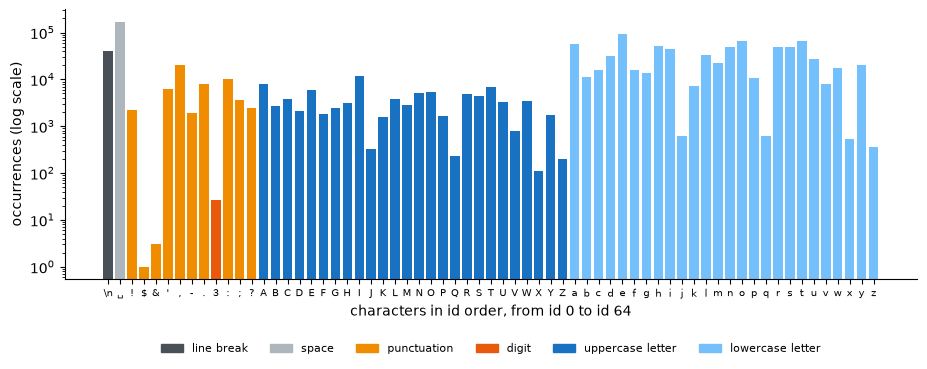

In [24]:
# What does an id say? Frequency of each id, in id order, coloured by the category of its character.
from matplotlib.patches import Patch

CATEGORY_COLOURS = {'line break': '#495057', 'space': '#adb5bd', 'punctuation': '#f08c00',
                    'digit': '#e8590c', 'uppercase letter': '#1971c2',
                    'lowercase letter': '#74c0fc'}

for category in CATEGORY_COLOURS:
    ids = [stoi[ch] for ch in chars if character_category(ch) == category]
    print(f'{category}: ids {min(ids)} to {max(ids)}')
print(f"'A' -> {stoi['A']}, 'a' -> {stoi['a']}")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(range(vocab_size), [counts[ch] for ch in chars],
       color=[CATEGORY_COLOURS[character_category(ch)] for ch in chars])
ax.set_yscale('log')
ax.set_xticks(range(vocab_size), [tick(ch) for ch in chars], fontsize=7)
ax.set_xlabel('characters in id order, from id 0 to id 64')
ax.set_ylabel('occurrences (log scale)')
legend = [Patch(color=colour, label=name) for name, colour in CATEGORY_COLOURS.items()]
ax.legend(handles=legend, fontsize=8, ncols=6, frameon=False, loc='upper center',
          bbox_to_anchor=(0.5, -0.2))
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Ids follow the character codes. The line break is 0, the space 1, the signs and the digit 2 to 12, the capitals 13 to 38 and the lowercase letters 39 to 64. Along the ids, the frequency jumps up and down, and `A` (13) sits far from `a` (39) although they are the same letter. So an id says nothing about how frequent a character is or how close two characters are. It only numbers a row, and the table of section 5 will have to learn what each row means.

I chose one token per character. I compare it with one token per word, the unit I used in my NLP TPs.

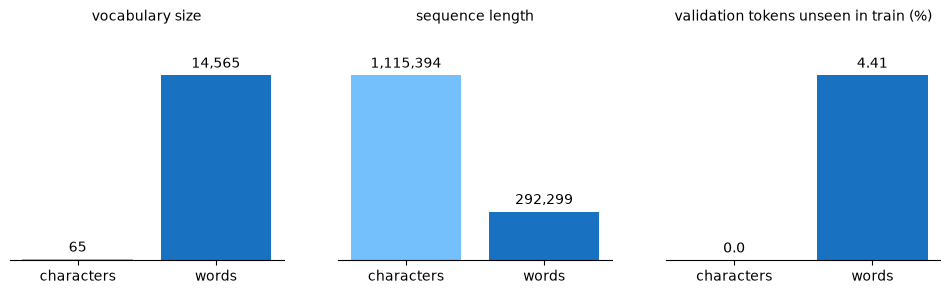

In [25]:
# Characters or words? Compare vocabulary size, sequence length and unseen tokens in validation.
WORD_PATTERN = r"[A-Za-z']+|[^A-Za-z'\s]|\n"  # a word, a single sign or a line break

tokenizers = {'characters': list, 'words': lambda s: re.findall(WORD_PATTERN, s)}
measures = {}
for name, tokenize in tokenizers.items():
    train_tokens, val_tokens = tokenize(text[:split_at]), tokenize(text[split_at:])
    known = set(train_tokens)
    unseen = sum(token not in known for token in val_tokens)
    measures[name] = [len(known | set(val_tokens)), len(train_tokens) + len(val_tokens),
                      percentage(unseen, len(val_tokens))]

titles = ['vocabulary size', 'sequence length', 'validation tokens unseen in train (%)']
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for k, (ax, title) in enumerate(zip(axes, titles)):
    values = [measures[name][k] for name in tokenizers]
    bars = ax.bar(list(tokenizers), values, color=['#74c0fc', '#1971c2'])
    ax.bar_label(bars, labels=[f'{value:,}' for value in values], padding=3)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, max(values) * 1.25)
    ax.set_yticks([])
    ax.spines[['top', 'right', 'left']].set_visible(False)
plt.show()

Character tokenisation produces 65 distinct tokens, while the word-oriented rule produces 14,565. With that rule, 4.41% of validation tokens are unseen in training. A fixed word vocabulary would need a way to represent them.

The character sequence contains 1,115,394 tokens against 292,299 for the alternative, about 3.8 times as many. This comparison also reflects the alternative rule's treatment of spaces, punctuation and line breaks.

I keep characters because their vocabulary is small and decoding preserves the text exactly. The cost is that a fixed number of tokens covers less text. Subword tokenisation offers another trade-off, which I do not test here.

> *My conclusion:*
>
> I now have a closed vocabulary of 65 characters, numbered in sorted order so that the ids stay the same at every run. `encode` turns the text into 1,115,394 ids without losing anything, and section 3 turns them into a tensor. An id is only a row number, so the table of section 5 has to learn what each row means.
>
> My answers to the two questions of this step:
>
> 1. I sort `chars` because a set has no stable order between runs, and a character must keep the same id so that the trained table and the decoding stay valid.
> 2. The round trip guarantees that encoding loses nothing on this vocabulary, since the two maps invert each other. It guarantees nothing for a character outside the vocabulary, which raises a KeyError.

## 3. Build the expected predictions

I need inputs whose answers come from the next character in the original text. I split the sequence before drawing windows so that overlapping windows cannot cross between training and validation. Then I inspect one example by hand.

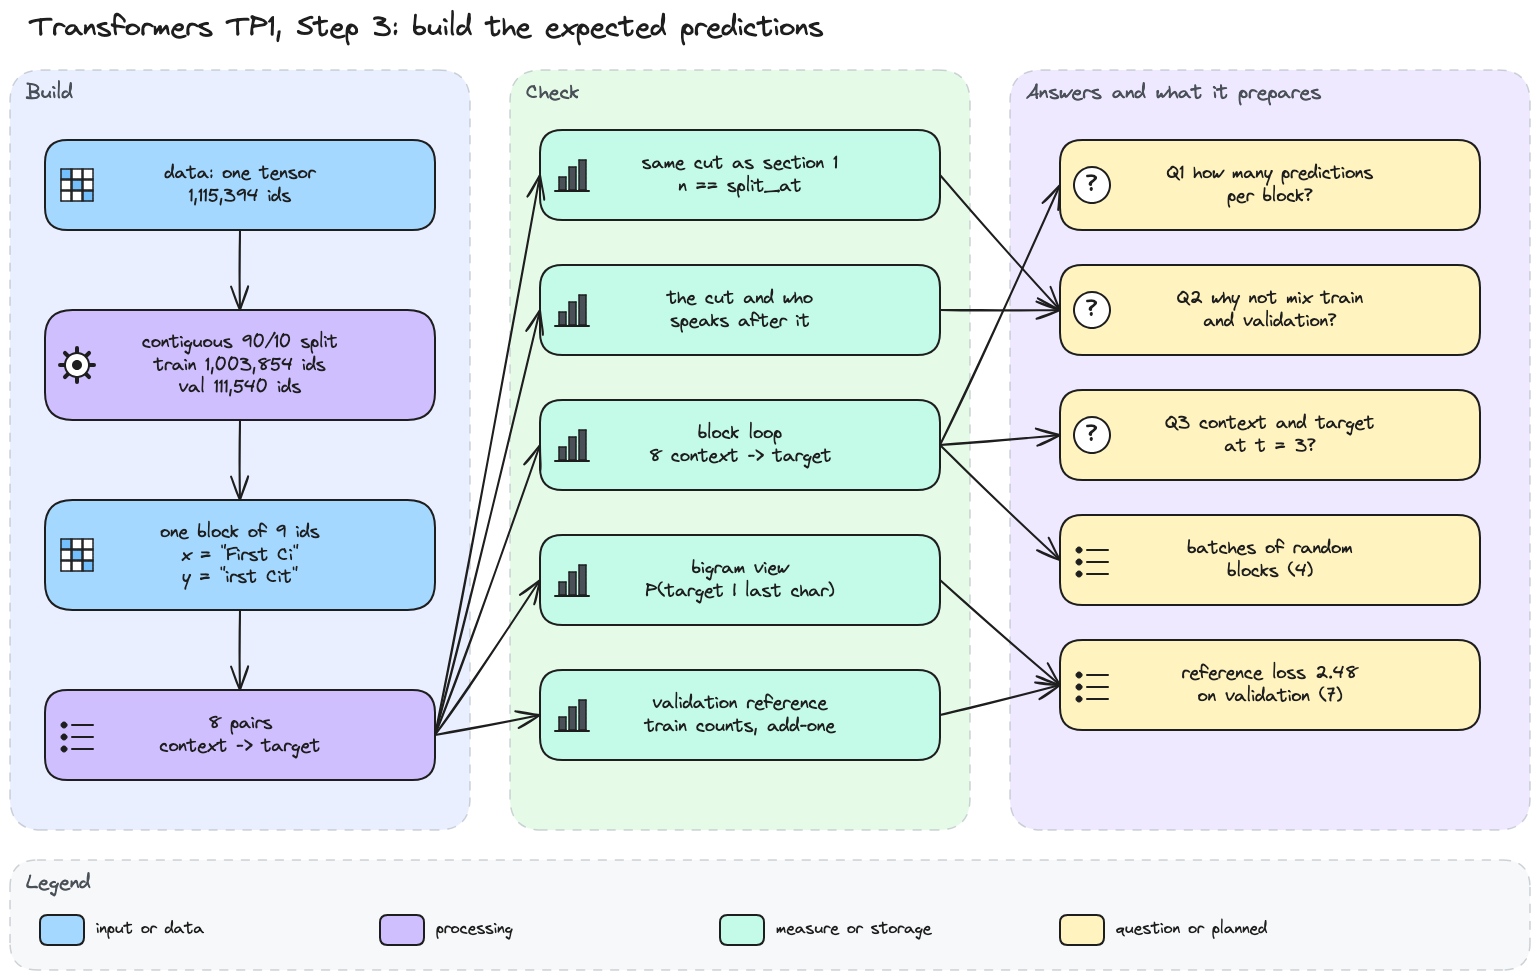

In [26]:
# Step 3 diagram: tensor, split, one block of predictions, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp1_step3.png', width=900))

In [27]:
# The whole text as one tensor of ids, then a 90/10 split by position.
data = torch.tensor(encode(text), dtype=torch.long)

n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

print(f'data: shape {tuple(data.shape)}, dtype {data.dtype}')
print(f'First ids: {data[:9].tolist()} -> {decode(data[:9].tolist())!r}')
print(f'train_data: {len(train_data):,} ids, val_data: {len(val_data):,} ids')
print(f'Same cut as split_at in section 1: {n == split_at}')

data: shape (1115394,), dtype torch.int64
First ids: [18, 47, 56, 57, 58, 1, 15, 47, 58] -> 'First Cit'
train_data: 1,003,854 ids, val_data: 111,540 ids
Same cut as split_at in section 1: True


The text is now one tensor of 1,115,394 ids, one per character, and its first ids decode back to `First Cit`. I keep the 64-bit integer type, because these ids will index the rows of the table in section 5. The cut gives 1,003,854 ids to train and 111,540 to validation, at the same place as `split_at` in section 1. So the check of section 1 still holds, and validation has no character missing from train.

The split takes the first 90% for train and the last 10% for validation, without shuffling. I want to see where this cut falls and what lies after it.

Before the cut: 'ntleman thus grieved as I?\nBut who comes here'
After the cut:  '?\n\nGREMIO:\nGood morrow, neighbour Baptista.\n\n'
Validation speakers: 36, never speaking in train: 24
Validation blocks they open: 367 of 919


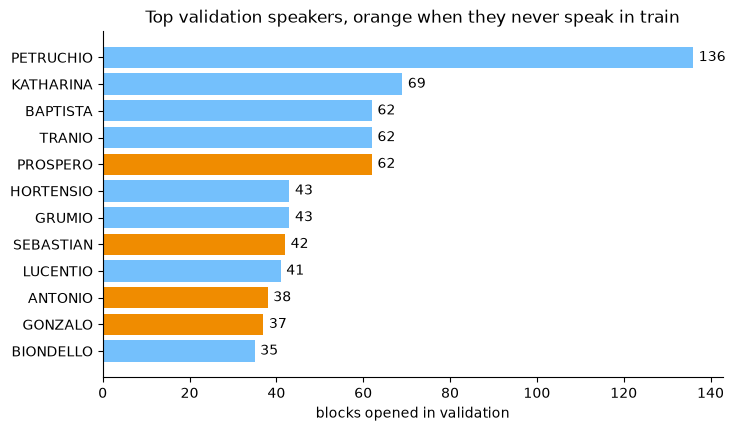

In [28]:
# Where does the cut fall, and who speaks on each side of it?
HEADER = r"(?:\A|\n\n)([A-Z][A-Za-z' ]*):\n"  # a name alone on the first line of a block

print(f'Before the cut: {decode(data[n - 45:n].tolist())!r}')
print(f'After the cut:  {decode(data[n:n + 45].tolist())!r}')

train_names = Counter(re.findall(HEADER, text[:n]))
val_names = Counter(re.findall(HEADER, text[n:]))
new_names = [name for name in val_names if name not in train_names]
print(f'Validation speakers: {len(val_names)}, never speaking in train: {len(new_names)}')
print(f'Validation blocks they open: {sum(val_names[name] for name in new_names)} '
      f'of {sum(val_names.values())}')

top = val_names.most_common(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh([name for name, _ in top], [count for _, count in top],
               color=['#f08c00' if name in new_names else '#74c0fc' for name, _ in top])
ax.bar_label(bars, padding=4)
ax.set_xlabel('blocks opened in validation')
ax.set_title('Top validation speakers, orange when they never speak in train')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The cut falls inside a sentence, between `But who comes here` and its question mark. Of the 36 validation speakers, 24 do not speak in training. They open 367 of the 919 validation blocks.

PETRUCHIO appears on both sides, while PROSPERO appears only in validation. Their 136 and 62 validation blocks help explain the increase in `P` observed in section 1.

Adjacent windows of 9 characters share 8 characters. Splitting those windows randomly would put near-duplicate passages on both sides, so I split the raw sequence first and sample inside each part.

This protects against overlapping-window leakage. It is still one contiguous holdout, with some shared speakers, rather than a separate collection of independent works. I next inspect exactly which prediction each position supplies.

In [29]:
# One block of the train set: x is the input, y the same characters shifted by one position.
block_size = 8
x = train_data[:block_size]
y = train_data[1:block_size + 1]

for t in range(block_size):
    context = x[:t + 1]
    target = y[t]
    print(context, "->", target, f"   {decode(context.tolist())!r} -> {itos[target.item()]!r}")

tensor([18]) -> tensor(47)    'F' -> 'i'
tensor([18, 47]) -> tensor(56)    'Fi' -> 'r'
tensor([18, 47, 56]) -> tensor(57)    'Fir' -> 's'
tensor([18, 47, 56, 57]) -> tensor(58)    'Firs' -> 't'
tensor([18, 47, 56, 57, 58]) -> tensor(1)    'First' -> ' '
tensor([18, 47, 56, 57, 58,  1]) -> tensor(15)    'First ' -> 'C'
tensor([18, 47, 56, 57, 58,  1, 15]) -> tensor(47)    'First C' -> 'i'
tensor([18, 47, 56, 57, 58,  1, 15, 47]) -> tensor(58)    'First Ci' -> 't'


The block uses 9 characters to supply 8 next-character predictions. At t = 3, the available prefix is `Firs`, represented by `[18, 47, 56, 57]`. Its target is `t`, with id 58.

The longer prefix contains the answers to earlier positions because those characters are now observed. The answer at the current position remains the next character. Shifting x and y aligns these questions and answers without changing their order.

The full training sequence contains 1,003,853 adjacent pairs. My bigram will only read the last character of each prefix. I next measure what information that restriction loses in this example.

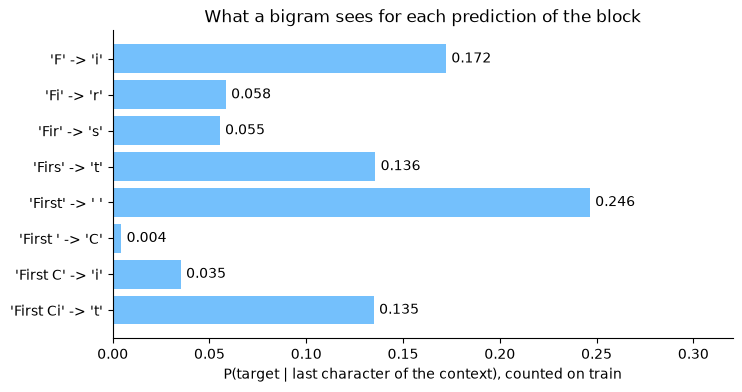

In [30]:
# What does the last character of each context say about its target? Pairs counted on train only.
train_pairs = torch.zeros((vocab_size, vocab_size))
train_pairs.index_put_((train_data[:-1], train_data[1:]), torch.ones(n - 1), accumulate=True)
train_probs = train_pairs / train_pairs.sum(dim=1, keepdim=True)

labels = [f'{decode(x[:t + 1].tolist())!r} -> {itos[y[t].item()]!r}' for t in range(block_size)]
probs = [train_probs[x[t], y[t]].item() for t in range(block_size)]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(labels[::-1], probs[::-1], color='#74c0fc')
ax.bar_label(bars, labels=[f'{p:.3f}' for p in probs[::-1]], padding=4)
ax.set_xlim(0, max(probs) * 1.3)
ax.set_xlabel('P(target | last character of the context), counted on train')
ax.set_title('What a bigram sees for each prediction of the block')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

For the prefix `First `, the counted bigram assigns only 0.004 to the target `C`. For `First`, it assigns 0.246 to the following space. The same model can therefore find adjacent positions very different in difficulty.

After `C`, it assigns 0.035 to `i`. A reader can use `First C` to anticipate `Citizen`, but this table only receives `C`. This gives me a specific reason to investigate longer contexts later.

Before changing the architecture, I need to know how well a table estimated from training already predicts validation.

In [31]:
# Build a training-count reference, with smoothing for unseen validation transitions.
val_seen = train_pairs[val_data[:-1], val_data[1:]] > 0
unseen = int((~val_seen).sum())
print(f'Validation pairs never seen in train: {unseen} of {len(val_data) - 1:,} '
      f'({percentage(unseen, len(val_data) - 1)}%)')

smoothed = (train_pairs + 1) / (train_pairs + 1).sum(dim=1, keepdim=True)  # add-one smoothing
train_loss = -torch.log(train_probs[train_data[:-1], train_data[1:]]).mean().item()
val_loss = -torch.log(smoothed[val_data[:-1], val_data[1:]]).mean().item()
print(f'Table counted on train, loss on train: {train_loss:.2f} nats')
print(f'Same table with add-one smoothing, loss on validation: {val_loss:.2f} nats')

Validation pairs never seen in train: 187 of 111,539 (0.17%)
Table counted on train, loss on train: 2.45 nats
Same table with add-one smoothing, loss on validation: 2.48 nats


Validation contains 187 transitions absent from training, or 0.17% of its 111,539 pairs. An unsmoothed count model assigns these events probability zero, so any one of them would give an infinite loss.

Add-one smoothing gives every possible follower a count before normalising each row. This reserves some probability for unseen pairs and slightly changes the probabilities of observed ones too.

The unsmoothed training-count model scores 2.45 nats on training. The smoothed version scores 2.48 on validation. I use 2.48 as a practical reference for this fitted model, not a mathematical lower bound on validation loss.

These scores use different distributions because validation requires smoothing. Their small difference is reassuring here, but it does not isolate the effect of new scenes or prove that both splits have identical distributions.

> *My conclusion:*
>
> I split the sequence into 1,003,854 training ids and 111,540 validation ids before sampling windows. Each input position predicts the following character, and the bigram uses only the current character to do so.
>
> The training counts provide a reference I can compare with learning by gradient updates. Their unsmoothed training loss is 2.45, while their smoothed validation loss is 2.48. Only the former is the empirical optimum for the pairs it was fitted on.
>
> My answers to the three questions of this step:
>
> 1. A block of 9 characters produces 8 predictions.
> 2. Splitting before sampling prevents overlapping windows from putting the same passage in both sets.
> 3. At t = 3, the prefix is `[18, 47, 56, 57]`, or `Firs`, and the target is 58, or `t`.

## 4. Sample a mini-batch

I stack B windows of length T to calculate their predictions together. I want to check both the alignment of their targets and the variability of the loss. That variability will affect how I judge training progress.

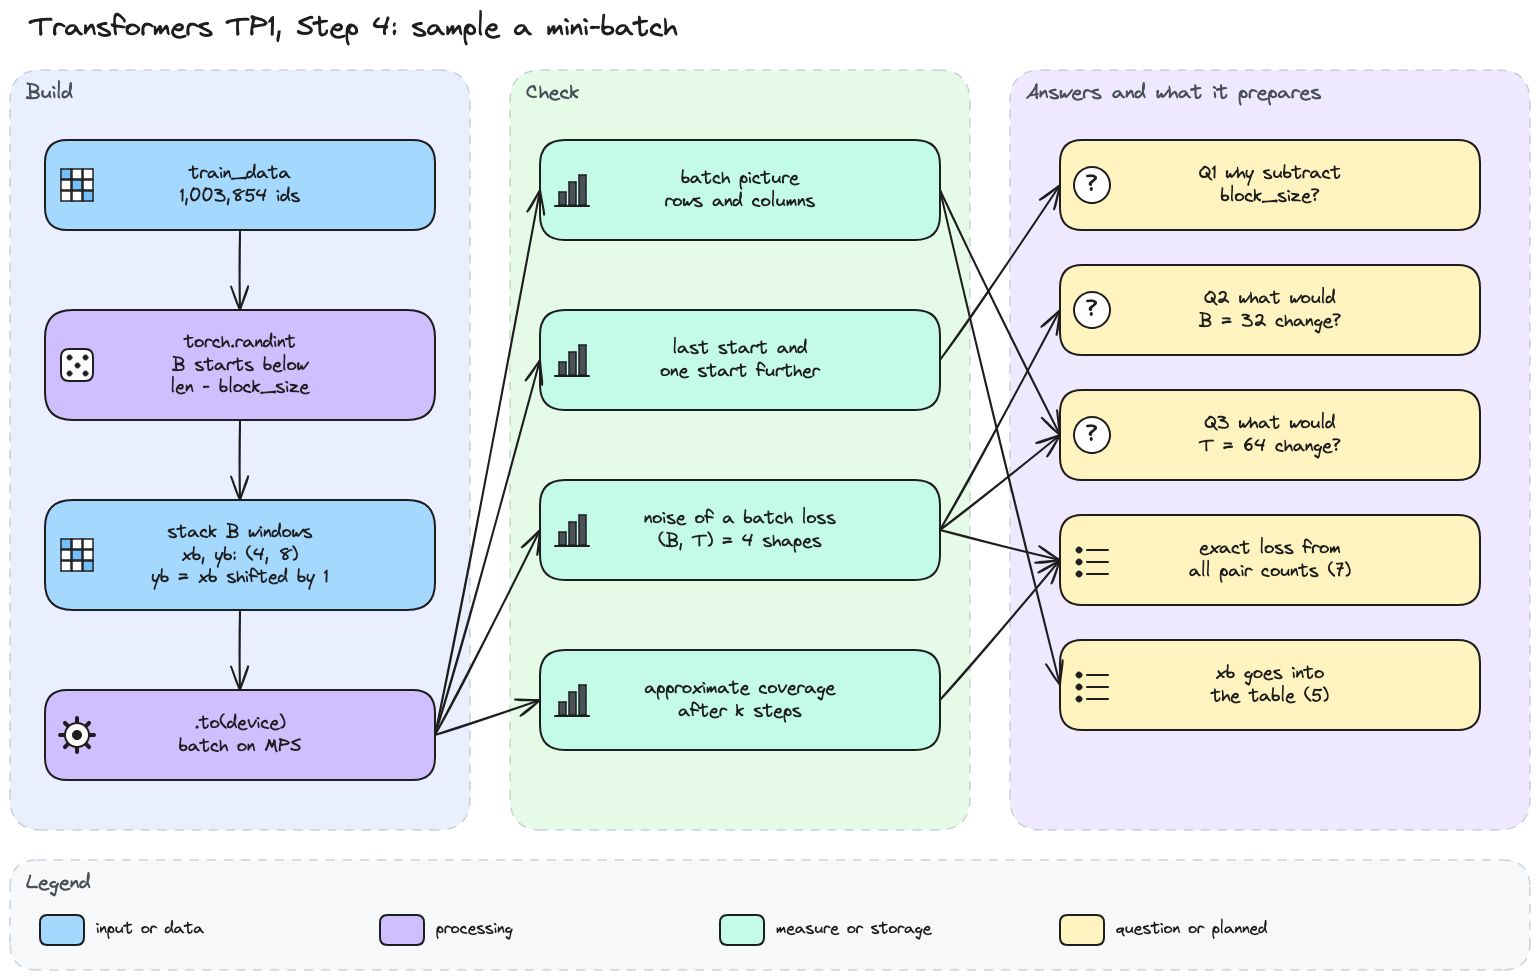

In [32]:
# Step 4 diagram: random starts, stacked windows, the device, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp1_step4.png', width=900))

In [33]:
# Mini-batches: B random blocks of length T from one split, sent to the device.
batch_size = 4
block_size = 8


def get_batch(split: str) -> tuple[torch.Tensor, torch.Tensor]:
    """B random blocks of one split as inputs x and targets y shifted by one position."""
    source = train_data if split == "train" else val_data
    starts = torch.randint(
        len(source) - block_size, (batch_size,)
    )
    x = torch.stack([
        source[i : i + block_size] for i in starts
    ])
    y = torch.stack([
        source[i + 1 : i + block_size + 1] for i in starts
    ])
    return x.to(device), y.to(device)


xb, yb = get_batch("train")
print(xb.shape, yb.shape)
print(f'device: {xb.device}, dtype: {xb.dtype}')

torch.Size([4, 8]) torch.Size([4, 8])
device: mps:0, dtype: torch.int64


Both tensors have shape (4, 8) and sit on the Apple GPU, with the same 64-bit ids as before. So one batch holds 4 × 8 = 32 predictions, against 8 for the single block of section 3. I want to see what the rows and the columns hold.

yb is xb shifted by one position: True
row 0: 's his lo' -> ' his lov'
row 1: ' there c' -> 'there ca'
row 2: 'ENCE:\nTo' -> 'NCE:\nTo '
row 3: 'st, with' -> 't, with\n'


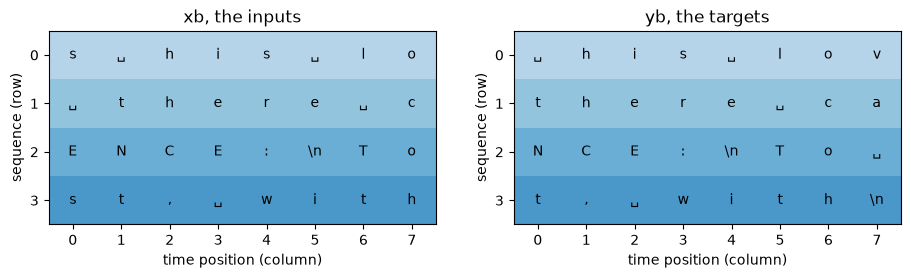

In [34]:
# What is inside a batch? Each row decoded, the shift checked, then xb and yb as character grids.
print(f'yb is xb shifted by one position: {torch.equal(yb[:, :-1], xb[:, 1:])}')
for row in range(batch_size):
    print(f'row {row}: {decode(xb[row].tolist())!r} -> {decode(yb[row].tolist())!r}')

fig, axes = plt.subplots(1, 2, figsize=(11, 2.8))
for ax, batch, name in ((axes[0], xb, 'xb, the inputs'), (axes[1], yb, 'yb, the targets')):
    ids = batch.cpu()
    shades = torch.arange(batch_size)[:, None].expand(-1, block_size)  # one shade per row
    ax.imshow(shades, cmap='Blues', vmin=-3, vmax=batch_size + 3)
    for row in range(batch_size):
        for col in range(block_size):
            ax.text(col, row, tick(itos[ids[row, col].item()]), ha='center', va='center')
    ax.set_xticks(range(block_size))
    ax.set_yticks(range(batch_size))
    ax.set_xlabel('time position (column)')
    ax.set_ylabel('sequence (row)')
    ax.set_title(name)
plt.show()

Each row comes from a randomly chosen position, such as `s his lo` or the name ending in `ENCE:\nTo`. The rows do not form one continuous passage. Two sampled windows can still overlap or contain related text.

The columns represent positions inside each window. The alignment check confirms that the first targets match the inputs one position to their right. Every position has its own loss term, although neighbouring characters are statistically related.

I next test the last allowed start and one position beyond it. A boundary example should reveal an indexing error more clearly than another random batch.

In [35]:
# Why subtract block_size? The last start torch.randint can draw, then one start further.
last = len(train_data) - block_size - 1
for i in (last, last + 1):
    x_row, y_row = train_data[i : i + block_size], train_data[i + 1 : i + block_size + 1]
    print(f'start {i:,}: x has {len(x_row)} ids, y has {len(y_row)} ids')

try:
    torch.stack([train_data[i + 1 : i + block_size + 1] for i in (last, last + 1)])
except RuntimeError as error:
    print(f'torch.stack fails: {error}')

start 1,003,845: x has 8 ids, y has 8 ids
start 1,003,846: x has 8 ids, y has 7 ids
torch.stack fails: stack expects each tensor to be equal size, but got [8] at entry 0 and [7] at entry 1


At start 1,003,845, both x and y contain 8 ids. Moving one place further leaves y with only 7, and stacking it with a full row fails.

The input and its shifted target together require `block_size + 1` characters starting at the chosen position. Since the upper bound of `torch.randint` is excluded, `len(source) - block_size` keeps both slices complete.

This check covers the boundary directly instead of waiting for a rare random draw to reach it. I now vary B and T while keeping the scoring table fixed.

B = 4, T = 8: 32 predictions, mean 2.45, std 0.203
B = 32, T = 8: 256 predictions, mean 2.45, std 0.072
B = 4, T = 64: 256 predictions, mean 2.45, std 0.072
B = 32, T = 64: 2048 predictions, mean 2.45, std 0.025


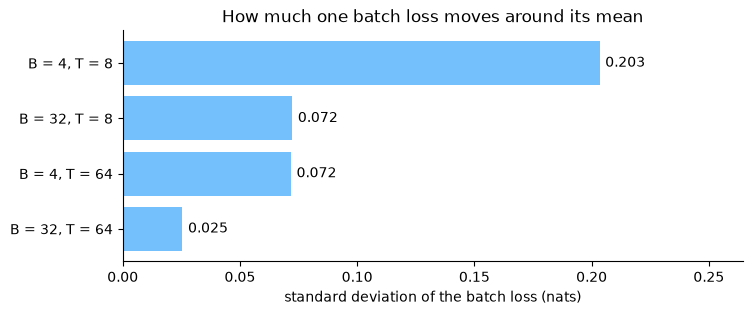

In [36]:
# What would B = 32 or T = 64 change? Spread of the section 3 table's loss over 2,000 batches.
position_loss = -torch.log(train_probs[train_data[:-1], train_data[1:]])  # predict i + 1 from i
SHAPES = [(4, 8), (32, 8), (4, 64), (32, 64)]

spreads = {}
for B, T in SHAPES:
    starts = torch.randint(len(train_data) - T, (2000, B))  # the same rule as get_batch
    windows = starts[:, :, None] + torch.arange(T)
    batch_losses = position_loss[windows].mean(dim=(1, 2))
    spreads[(B, T)] = batch_losses.std().item()
    print(f'B = {B}, T = {T}: {B * T} predictions, mean {batch_losses.mean():.2f}, '
          f'std {spreads[(B, T)]:.3f}')

labels = [f'B = {B}, T = {T}' for B, T in SHAPES][::-1]
values = [spreads[shape] for shape in SHAPES][::-1]
fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.barh(labels, values, color='#74c0fc')
ax.bar_label(bars, labels=[f'{value:.3f}' for value in values], padding=4)
ax.set_xlim(0, max(values) * 1.3)
ax.set_xlabel('standard deviation of the batch loss (nats)')
ax.set_title('How much one batch loss moves around its mean')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

All four batch shapes give a mean near 2.45 for the same counted model. With B = 4 and T = 8, the standard deviation is 0.203 nats. One batch can therefore give a misleading impression of a small improvement.

Increasing B to 32 gives 256 predictions and a standard deviation of 0.072, about 2.8 times smaller. Increasing T to 64 also gives 256 predictions and 0.072 in this experiment.

The reduction is close to the square-root rule for independent observations, but neighbouring characters are correlated. I treat these values as measurements for this corpus and scoring table. They do not directly measure gradient variability.

The larger shapes use eight times as many input and target elements. This does not mean total memory use increases eightfold, since the model and optimiser also occupy memory.

A larger T supplies longer prefixes, but this bigram still ignores their earlier characters. In section 7 I will use the exact count-weighted loss on each split, which is inexpensive for this small table.

B = 4, T = 8, 100 steps: 3,200 predictions, about 0.32% of train positions seen
B = 4, T = 8, 1,000 steps: 32,000 predictions, about 3.14% of train positions seen
B = 32, T = 8, 100 steps: 25,600 predictions, about 2.52% of train positions seen
B = 32, T = 8, 1,000 steps: 256,000 predictions, about 22.51% of train positions seen


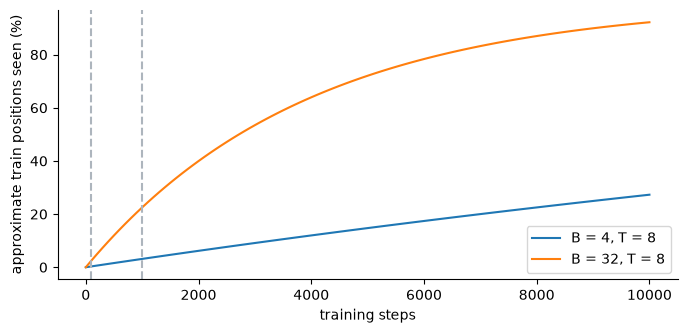

In [37]:
# How much of train do the steps of section 7 see? Each step draws B * T positions at random,
# so a position stays unseen after k steps with probability about exp(-k * B * T / n).
steps = torch.arange(0, 10_001, 100)

fig, ax = plt.subplots(figsize=(8, 3.5))
for B, T in ((4, 8), (32, 8)):
    ax.plot(steps, 100 * (1 - torch.exp(-steps * B * T / n)), label=f'B = {B}, T = {T}')
    for k in (100, 1_000):
        share = 100 * (1 - math.exp(-k * B * T / n))
        print(f'B = {B}, T = {T}, {k:,} steps: {k * B * T:,} predictions, '
              f'about {share:.2f}% of train positions seen')
for k in (100, 1_000):
    ax.axvline(k, color='#adb5bd', linestyle='--')  # 100 and 1,000 steps
ax.set_xlabel('training steps')
ax.set_ylabel('approximate train positions seen (%)')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

At B = 4 and T = 8, 100 updates process 3,200 predictions and 1,000 updates process 32,000. Repeated draws can revisit positions, so this is a count of training events, not unique characters seen.

The coverage approximation gives 0.32% and 3.14% of training positions. It treats position visits approximately and ignores boundary differences. The code does not record the actual set of visited positions.

Dividing 32,000 events by 1,403 observed pair types gives about 23 per type, but the pairs are very unevenly distributed. I cannot infer that each type receives that many updates.

With B = 32, the estimate reaches 22.51% after 1,000 updates. This raises another explanation for slow learning, the number of examples processed. I will compare batch size and learning rate in section 7.

> *My conclusion:*
>
> `get_batch` returns aligned inputs and targets from one split. At B = 4 and T = 8, it supplies 32 loss terms. Scoring them separately does not make the underlying observations independent.
>
> The measured batch-loss variability makes the last training loss an unreliable summary. I will evaluate every pair in each split through its counts. Coverage remains an approximation, and a larger batch also processes more examples per update.
>
> My answers to the three questions of this step:
>
> 1. The excluded upper bound leaves enough characters for both full-length slices.
> 2. B = 32 gives a shape of (32, 8), with 256 predictions and a measured loss standard deviation of 0.072 instead of 0.203.
> 3. T = 64 gives (4, 64) and the same number of predictions, but the bigram still uses only one character at each position.

## 5. Produce logits with a table

Each input id selects a row with one score per possible next character. These scores are called logits. I first check that the code performs this lookup, then follow one prediction from its scores to its loss.

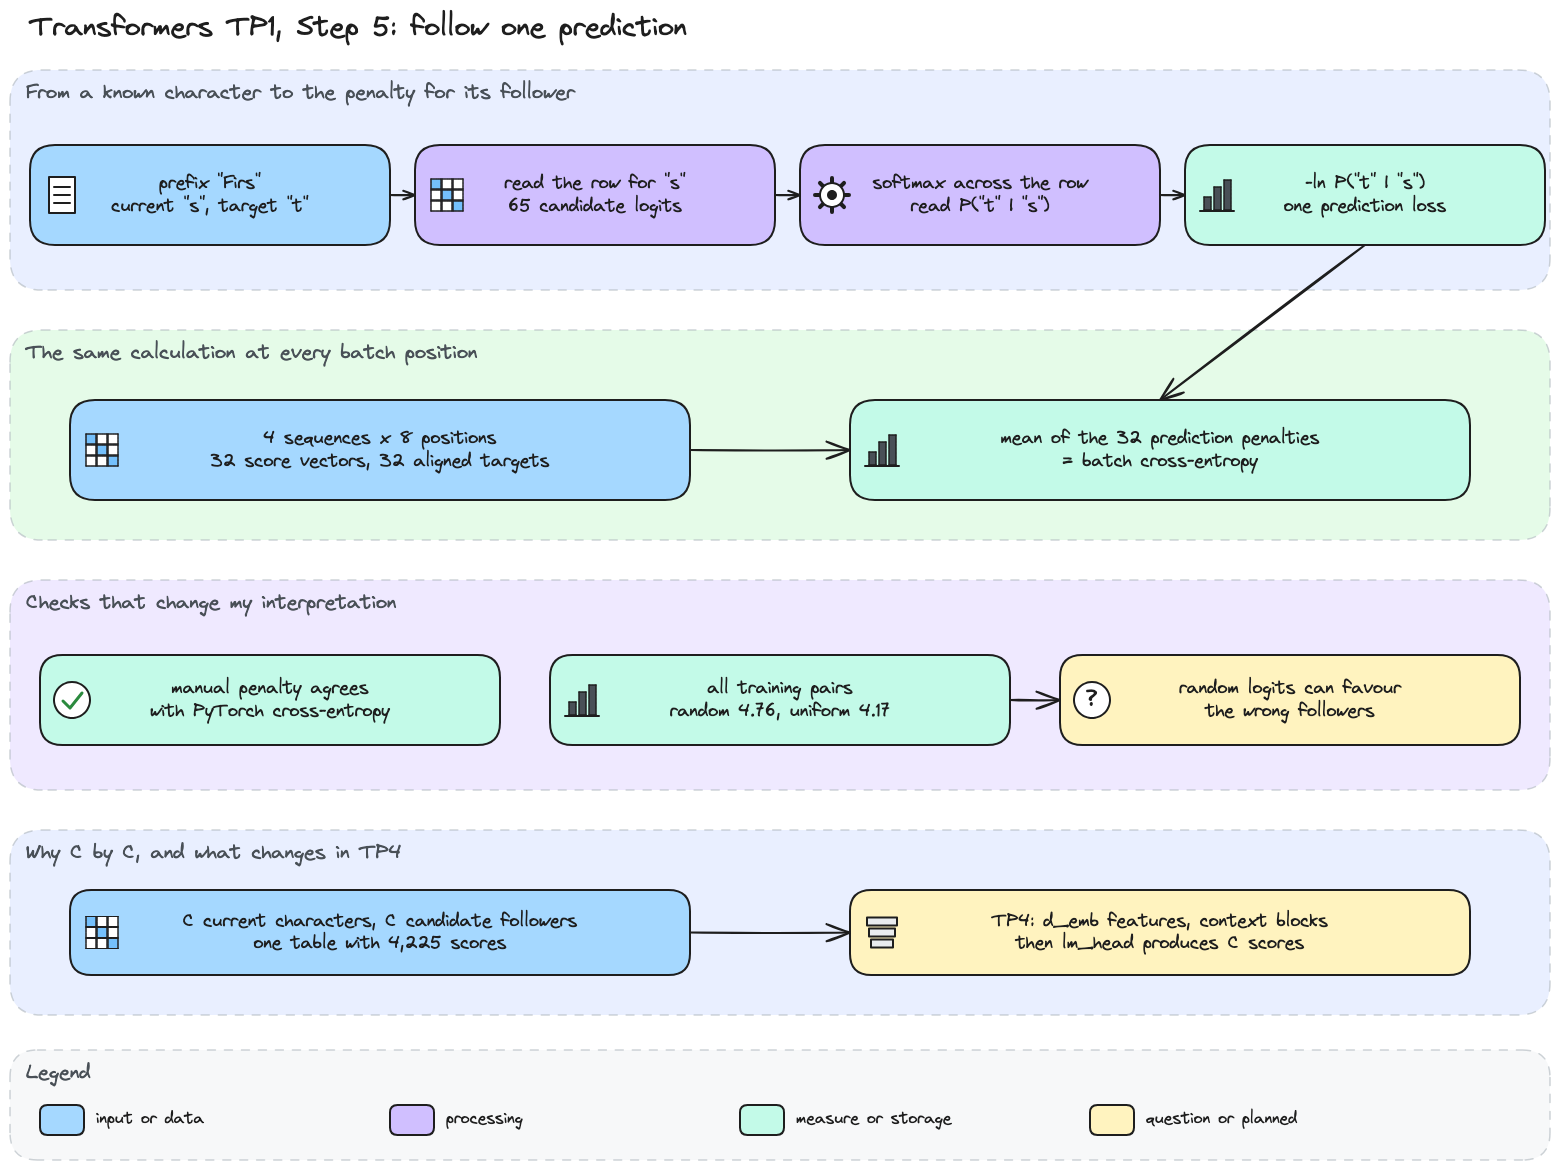

In [38]:
# Step 5 diagram: ids, table, logits and loss, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp1_step5.png', width=900))

In [39]:
# The bigram model: an embedding table of C x C whose rows are directly the logits.
import torch.nn as nn
import torch.nn.functional as F


class BigramLanguageModel(nn.Module):
    """Bigram model: each character picks one row of scores for the next character."""

    def __init__(self, vocab_size: int):
        super().__init__()
        self.token_embedding_table = nn.Embedding(
            vocab_size, vocab_size
        )

    def forward(self, idx: torch.Tensor, targets: torch.Tensor | None = None):
        """Logits for the ids idx, and the cross-entropy loss when targets are given."""
        logits = self.token_embedding_table(idx)
        # idx: (B,T) -> logits: (B, T, C)
        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)
        return logits, loss

    @torch.no_grad()
    def generate(self, idx: torch.Tensor, max_new_tokens: int) -> torch.Tensor:
        """Extend idx by max_new_tokens ids, each drawn from the scores of the last position."""
        for _ in range(max_new_tokens):
            logits, _ = self(idx)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(
                probs, num_samples=1
            )
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

In [40]:
# Build the table from a fresh seed, then run one batch without and with targets.
torch.manual_seed(RANDOM_STATE)  # the starting table only depends on the seed
model = BigramLanguageModel(vocab_size).to(device)

logits, _ = model(xb)
flat_logits, loss = model(xb, yb)
table = model.token_embedding_table.weight

print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')
print(f'xb {tuple(xb.shape)} -> logits {tuple(logits.shape)}')
print(f'With targets: logits {tuple(flat_logits.shape)}, targets {tuple(yb.view(-1).shape)}')
print(f'Loss on this batch: {loss.item():.2f}')
print(f'Each position reads the row of its character: {torch.equal(logits, table[xb])}')

Parameters: 4,225
xb (4, 8) -> logits (4, 8, 65)
With targets: logits (32, 65), targets (32,)
Loss on this batch: 4.89
Each position reads the row of its character: True


The table contains 4,225 parameters, arranged in 65 rows and 65 columns. The batch shape (4, 8) becomes (4, 8, 65), with one vector of scores per input position.

Flattening B and T gives 32 score vectors and 32 target ids for cross-entropy. It changes the arrangement used by the loss function, while preserving which target belongs to each vector.

The lookup check is True. Each occurrence of a character receives the same row, regardless of earlier characters. This verifies the model's restriction directly, before I interpret any generated text.

The table has C rows for current characters and C columns for candidate next characters. In TP4, `token_embedding_table` will instead provide `d_emb` features. Context-processing blocks and `lm_head` will then turn those features into C scores.

This batch loss is 4.89. Before comparing it with my uniform reference, I trace the `s` to `t` prediction from the prefix `Firs`.

In [41]:
# Trace the existing prefix Firs and target t through one detached row of the model.
demo_current, demo_target = stoi['s'], stoi['t']
demo_row = model.token_embedding_table.weight[demo_current].detach().cpu().clone()
demo_probs = F.softmax(demo_row, dim=0)
demo_nll = -torch.log(demo_probs[demo_target])
demo_ce = F.cross_entropy(demo_row[None, :], torch.tensor([demo_target]))
print(f"Prefix 'Firs', current id {demo_current} ('s'), target id {demo_target} ('t')")
print(f'Target logit: {demo_row[demo_target]:.4f}; probability: {demo_probs[demo_target]:.4f}')
print(f'Probability sum across {vocab_size} followers: {demo_probs.sum():.4f}')
print(f'Negative log probability: {demo_nll:.4f}; cross-entropy: {demo_ce:.4f} nats')
assert torch.allclose(demo_probs.sum(), torch.tensor(1.0))
assert torch.allclose(demo_nll, demo_ce)

Prefix 'Firs', current id 57 ('s'), target id 58 ('t')
Target logit: 1.0615; probability: 0.0267
Probability sum across 65 followers: 1.0000
Negative log probability: 3.6249; cross-entropy: 3.6249 nats


I select the row for `s` and the target column for `t`. The target logit is 1.0615, but its probability is only 0.0267 after softmax compares all candidate scores. A logit alone is therefore not a probability.

The negative log probability is 3.6249 nats, which agrees with cross-entropy. The same calculation is repeated at every position and then averaged. PyTorch receives the raw logits because cross-entropy already includes their normalisation.

This copied row leaves the model unchanged. I now evaluate all training pairs to check whether the initial batch loss represents the full split.

ln(65) = 4.17 nats
Untrained table on all train pairs: 4.76 nats
500 batch losses: mean 4.76, std 0.17, from 4.24 to 5.20


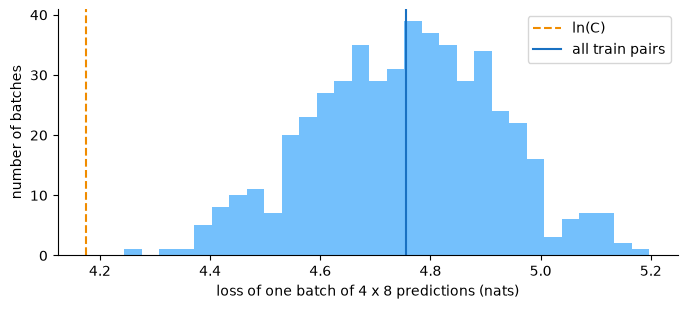

In [42]:
# Is the loss before training close to ln(C)? All train pairs at once, then 500 batch losses.
with torch.no_grad():
    weights = model.token_embedding_table.weight.cpu()
    # The loss of a bigram table only depends on how often each pair occurs (section 3).
    full_loss = (-(train_pairs * F.log_softmax(weights, dim=1)).sum()
                 / train_pairs.sum()).item()
    batch_losses = torch.tensor([model(*get_batch("train"))[1].item() for _ in range(500)])

print(f'ln({vocab_size}) = {math.log(vocab_size):.2f} nats')
print(f'Untrained table on all train pairs: {full_loss:.2f} nats')
print(f'500 batch losses: mean {batch_losses.mean():.2f}, std {batch_losses.std():.2f}, '
      f'from {batch_losses.min():.2f} to {batch_losses.max():.2f}')

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(batch_losses, bins=30, color='#74c0fc')
ax.axvline(math.log(vocab_size), color='#f08c00', linestyle='--', label='ln(C)')
ax.axvline(full_loss, color='#1971c2', label='all train pairs')
ax.set_xlabel('loss of one batch of 4 x 8 predictions (nats)')
ax.set_ylabel('number of batches')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The exact training loss is 4.76 nats, 0.59 above the uniform reference of 4.17. The 500 batch estimates average 4.76 but range from 4.24 to 5.20, with a standard deviation of 0.17.

My initial expectation was too optimistic. A batch near 4.24 could have appeared to support it, so checking all pairs changes my conclusion. The discrepancy persists after reducing sampling uncertainty.

I now test the assumption behind that expectation. Do random logits actually give probabilities close to equal? I inspect their softmax and compare with an explicitly uniform table.

Weights: mean 0.00, std 1.00
Largest probability in a row, on average: 0.101, uniform: 0.0154
Approximate loss for random scores of std 1: 4.67 nats
Table of zeros on all train pairs: 4.17 nats


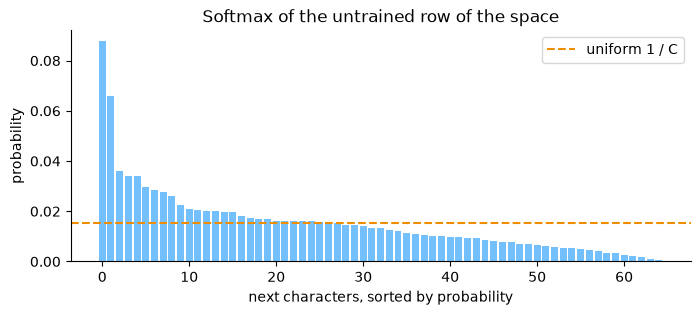

In [43]:
# Why is a random table not uniform? Softmax of the space row, sorted, against the uniform 1 / C.
probs = F.softmax(weights, dim=1)
space_row = probs[stoi[' ']].sort(descending=True).values
zero_loss = (-(train_pairs * F.log_softmax(torch.zeros_like(weights), dim=1)).sum()
             / train_pairs.sum()).item()

print(f'Weights: mean {weights.mean():.2f}, std {weights.std():.2f}')
print(f'Largest probability in a row, on average: {probs.max(dim=1).values.mean():.3f}, '
      f'uniform: {1 / vocab_size:.4f}')
# Scores of std 1: the log of the sum of their exponentials is about ln(C) + 1/2, while the
# score of the target is 0 on average, so each prediction costs about ln(C) + 0.5.
print(f'Approximate loss for random scores of std 1: {math.log(vocab_size) + 0.5:.2f} nats')
print(f'Table of zeros on all train pairs: {zero_loss:.2f} nats')

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(range(vocab_size), space_row, color='#74c0fc')
ax.axhline(1 / vocab_size, color='#f08c00', linestyle='--', label='uniform 1 / C')
ax.set_xlabel('next characters, sorted by probability')
ax.set_ylabel('probability')
ax.set_title('Softmax of the untrained row of the space')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The initial weights have mean 0 and standard deviation 1. That does not make the scores within each row equal. Softmax amplifies their differences because it exponentiates the scores before normalising them.

The largest probability in a row averages 0.101, compared with 0.0154 under a uniform distribution. These random preferences have no learned relationship with the target, so confidence can increase the loss.

The approximation ln(C) + 0.5 gives 4.67 nats, near the observed 4.76. It explains the scale of the discrepancy but is not an exact prediction for this particular table.

Setting every score to zero gives exactly 4.17. Any constant score within a row produces the same uniform probabilities. I therefore revise my assumption about random initialisation while keeping the uniform distribution as a useful control.

Distance from the start to the count reference on train: 2.30 nats


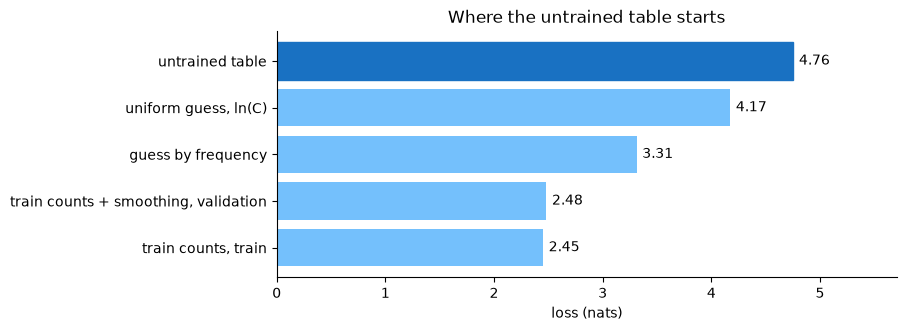

In [44]:
# Where does the untrained table start? Its loss against the levels of sections 1 and 3.
levels = {'untrained table': full_loss, 'uniform guess, ln(C)': math.log(vocab_size),
          'guess by frequency': entropy, 'train counts + smoothing, validation': val_loss,
          'train counts, train': train_loss}
names, values = list(levels)[::-1], list(levels.values())[::-1]
print(f'Distance from the start to the count reference on train: {full_loss - train_loss:.2f} nats')

fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.barh(names, values, color='#74c0fc')
bars[-1].set_color('#1971c2')  # the untrained table, on top
ax.bar_label(bars, labels=[f'{value:.2f}' for value in values], padding=4)
ax.set_xlim(0, max(values) * 1.2)
ax.set_xlabel('loss (nats)')
ax.set_title('Where the untrained table starts')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The initial loss exceeds the uniform reference. Its distance from the empirical training optimum is 2.30 nats. The frequency-only model provides another reference between uniform guessing and the counted bigram.

These levels help me interpret a decrease, but they do not prove that training learns in distinct stages. Several patterns can change together. I will use the curves and samples to see what the measured progress means.

The training-count model's validation score of 2.48 is a comparison point. It is not a barrier that another fitted model is mathematically unable to cross.

> *My conclusion:*
>
> The model selects one row per character, and cross-entropy penalises a low probability for the correct follower. Flattening preserves the input-target alignment across the 32 positions.
>
> Random initialisation gives 4.76 nats here, compared with 4.17 for uniform probabilities. The zero-score control shows why my initial explanation was wrong. I keep the original random table for the remaining experiments.
>
> My answers to the two questions of this step:
>
> 1. C current characters each need scores for C possible followers, so the table is C by C.
> 2. TP4 separates the `d_emb` features in `token_embedding_table` from the final C scores produced by `lm_head` after context processing.

## 6. Generate before training

I generate with the untrained table to establish a reference sample. The procedure starts from a line break, samples a follower, appends it and repeats. I keep this procedure and seed fixed for the later checkpoints.

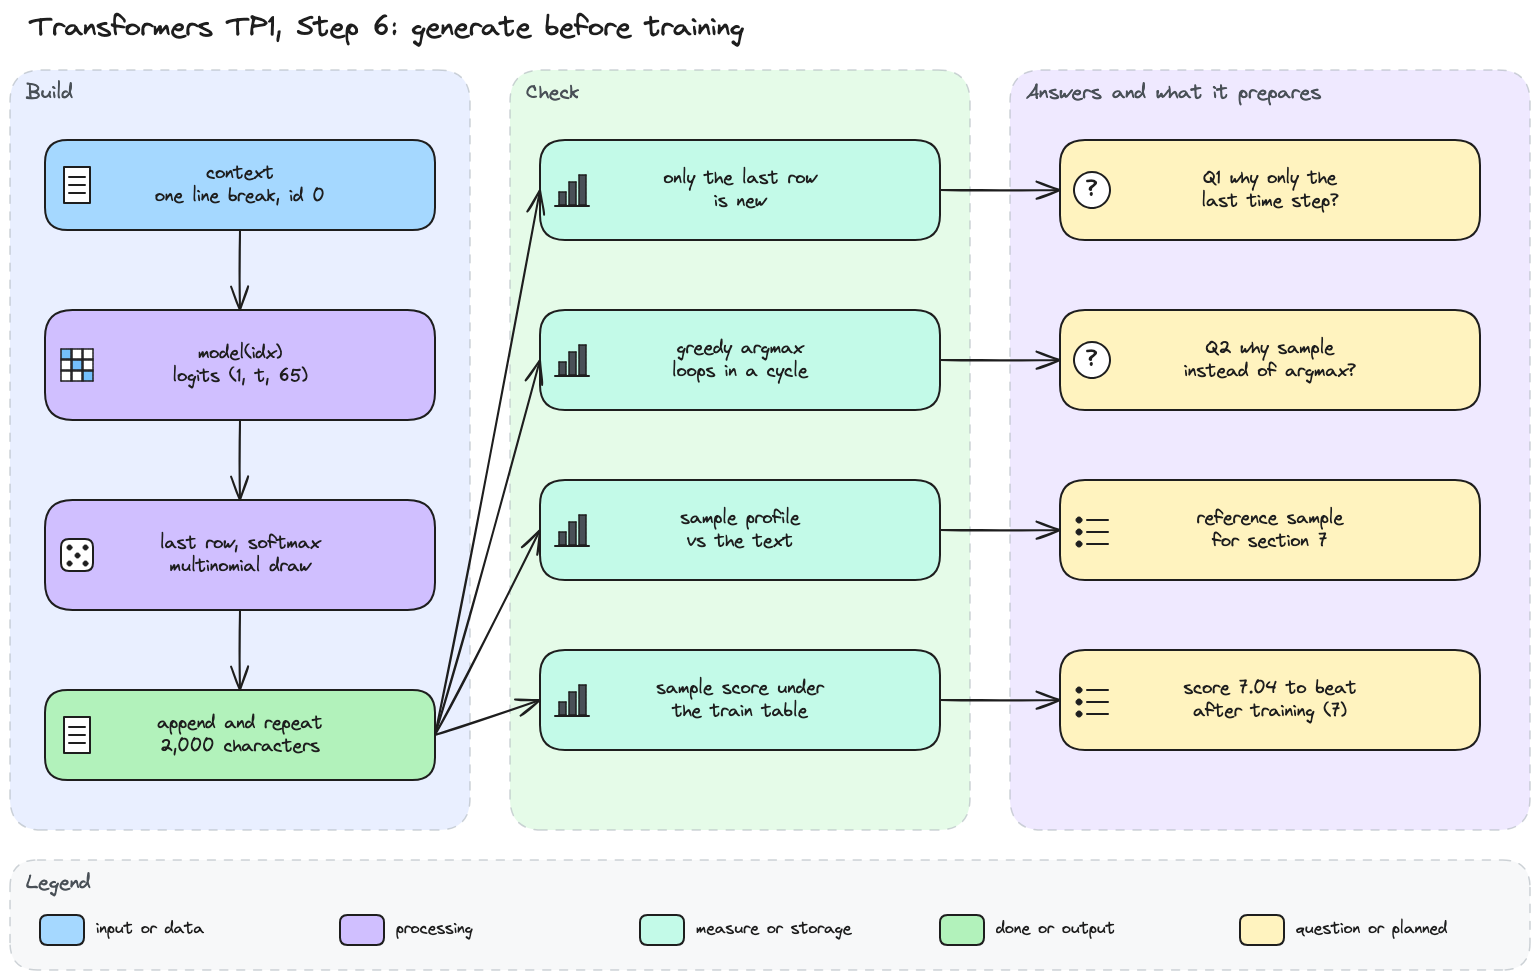

In [45]:
# Step 6 diagram: the generation loop and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp1_step6.png', width=900))

In [46]:
# Generate 2,000 characters from a single line break with the untrained table.
torch.manual_seed(RANDOM_STATE)  # the same sample at every run
context = torch.zeros((1, 1), dtype=torch.long, device=device)  # id 0 is the line break
sample_ids = model.generate(context, max_new_tokens=2000)[0].tolist()
sample = decode(sample_ids)

print(f'Generated: {len(sample_ids) - 1:,} characters after the context')
print(sample[:300])

Generated: 2,000 characters after the context

X;wVzBZxtXtKOY?nMHH$imWClMLKLoiCEavkET'-r$ijdO'Xn'3sdtueXccQHc,qnwdJnUN
  ;
!tZi y$,gzNwH$J
S:wyci3GPM
Dp&ZnERV!,BGOMvs!,iHLi3CYwVmG$AQz&xgJpcxW-m3UXz,BnCgZ&PHLapEZx?Q..:mP?AsYDJKU.'ir:mtQHLXaxgucQDxLMDvTBX!,FA'gHuordVlI;fOMq J&iqjvaP:rM,gSVHPTWe'g.jhCY3Z-MZUp-JnYxnK3Lg..Th&JPAOEm:gHcN TJq'JPwuo,Zi


The extract contains mixed capitals, letters and signs, such as `X;wVzBZxtXtKOY?nMHH$im`. I do not see readable dialogue in it. I will also measure its character profile and transitions so that the comparison does not depend only on this extract.

Generation uses `@torch.no_grad()` because it does not update weights. PyTorch therefore does not need to store the operations for a backward pass.

The method receives the growing context but keeps only the last output row. I next check which question that row answers.

In [47]:
# Why keep only the last time step? The logits of a context of 8 characters, row by row.
idx = torch.tensor([encode("First Ci")], device=device)
with torch.no_grad():
    logits, _ = model(idx)

print(f'Context of {idx.shape[1]} characters -> logits {tuple(logits.shape)}')
print(f'The last row is the table row of {decode([idx[0, -1].item()])!r}: '
      f'{torch.equal(logits[:, -1, :], table[idx[:, -1]])}')
print(f'Rows 0 to 6 predict characters already in the context: {decode(idx[0, 1:].tolist())!r}')

Context of 8 characters -> logits (1, 8, 65)
The last row is the table row of 'i': True
Rows 0 to 6 predict characters already in the context: 'irst Ci'


The context `First Ci` gives a tensor of shape (1, 8, 65). Its first seven rows predict characters already present later in that context. Only the final row predicts the character that has not yet been appended.

For this bigram, the last row equals the table row for `i`, as the check confirms. Earlier context cannot change it. The interface still returns all positions, which will also be useful for models that combine context later.

I next compare sampling with always taking the highest-scoring character. This changes the decoding decision while leaving the weights fixed.

In [48]:
# Why draw with multinomial instead of taking the most likely character? Greedy from a line break.
current, greedy_ids = 0, [0]
with torch.no_grad():
    for _ in range(60):
        current = int(table[current].argmax())
        greedy_ids.append(current)
print(repr(decode(greedy_ids)))

first_seen = {}
for step, char_id in enumerate(greedy_ids):
    if char_id in first_seen:
        print(f'Cycle from step {first_seen[char_id]}, length {step - first_seen[char_id]}')
        break
    first_seen[char_id] = step

'\ngZ&XhSkJ\ngZ&XhSkJ\ngZ&XhSkJ\ngZ&XhSkJ\ngZ&XhSkJ\ngZ&XhSkJ\ngZ&XhS'
Cycle from step 0, length 9


Greedy decoding repeats the cycle `\ngZ&XhSkJ`, with length 9. Each character has one fixed highest-scoring follower. Revisiting a character therefore repeats the same future path in this bigram.

Sampling can choose different followers from the same row, so it avoids being forced along one fixed cycle. It can still produce repetitive or poor text. I keep sampling for checkpoint comparisons and inspect its output rather than assuming variety means quality.

line break: text 3.59%, untrained sample 1.35%
space: text 15.23%, untrained sample 1.5%
punctuation: text 4.88%, untrained sample 15.19%
digit: text 0.0%, untrained sample 1.95%
uppercase letter: text 7.96%, untrained sample 40.18%
lowercase letter: text 68.35%, untrained sample 39.83%


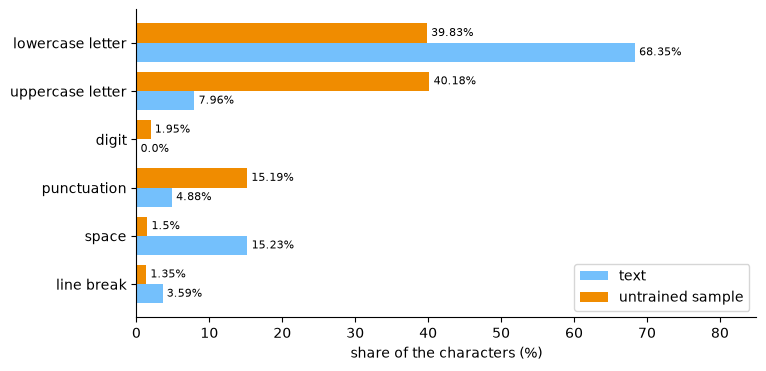

In [49]:
# What does the untrained sample look like? Character categories, sample against the whole text.
sample_occurrences = Counter(character_category(char) for char in sample)
text_shares = {cat: percentage(occurrences[cat], len(text)) for cat in CATEGORY_COLOURS}
sample_shares = {cat: percentage(sample_occurrences[cat], len(sample)) for cat in CATEGORY_COLOURS}
for cat in CATEGORY_COLOURS:
    print(f'{cat}: text {text_shares[cat]}%, untrained sample {sample_shares[cat]}%')

rows = torch.arange(len(CATEGORY_COLOURS))
fig, ax = plt.subplots(figsize=(8, 4))
for offset, shares, name, colour in ((-0.2, text_shares, 'text', '#74c0fc'),
                                     (0.2, sample_shares, 'untrained sample', '#f08c00')):
    bars = ax.barh(rows + offset, list(shares.values()), height=0.4, color=colour, label=name)
    ax.bar_label(bars, labels=[f'{share}%' for share in shares.values()], padding=3, fontsize=8)
ax.set_yticks(rows, list(CATEGORY_COLOURS))
ax.set_xlim(0, 85)
ax.set_xlabel('share of the characters (%)')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Capitals and lowercase letters occupy 40.18% and 39.83% of the sample. In the corpus, their shares are 7.96% and 68.35%. Spaces and line breaks are also much less frequent in the sample.

Having 26 capital tokens among 65 makes the sample's capital share resemble uniform sampling at the category level. Section 5 showed that individual rows still have unequal probabilities. Similar category totals do not imply a uniform distribution within each row.

This profile measures how often characters occur, without checking their order. I therefore add a score based on neighbouring pairs.

In [50]:
# How far is the sample from Shakespeare? Its pairs scored by the add-one table of section 3.
sample_tensor = torch.tensor(sample_ids)
sample_score = -torch.log(smoothed[sample_tensor[:-1], sample_tensor[1:]]).mean().item()
print(f'Untrained sample: {sample_score:.2f} nats per character')
print(f'Real validation text: {val_loss:.2f} nats per character')

Untrained sample: 7.04 nats per character
Real validation text: 2.48 nats per character


Under the smoothed training-count model, the generated sample scores 7.04 nats per character, compared with 2.48 for real validation text. Its transitions are therefore much less plausible to this reference model.

This calculation uses a fixed scoring table and changes the text being scored. Validation loss instead scores fixed validation text with the model at each checkpoint. Keeping these roles separate helps me avoid interpreting both numbers as the same measurement.

A lower sample score would show more locally plausible pairs. It would not establish coherent sentences, correct names or a match to the full text distribution. Even repetitive text can favour common transitions, so I will read the samples as well.

> *My conclusion:*
>
> I now have a fixed generation procedure and an untrained reference. Its character profile differs from the corpus, and its transitions score 7.04 nats under the smoothed training-count model.
>
> These measurements describe different aspects of the output. I will combine them with reading the extracts instead of treating a single score as a complete measure of language quality.
>
> My answers to the two questions this step raises:
>
> 1. The last row predicts the next character beyond the context. Earlier rows predict characters already present.
> 2. Sampling allows different followers from one row. Greedy decoding fixes one follower per character and produces a cycle of length 9 here.

## 7. Train, then compare

I first inspect the gradient of one prediction to understand what learning tries to correct. Then I train the original table with AdamW and measure exact losses on both splits.

I compare checkpoints before training, after 100 updates and after 1,000. The generation procedure stays fixed. Further experiments will depend on whether the table approaches its count-based reference and whether the samples change.

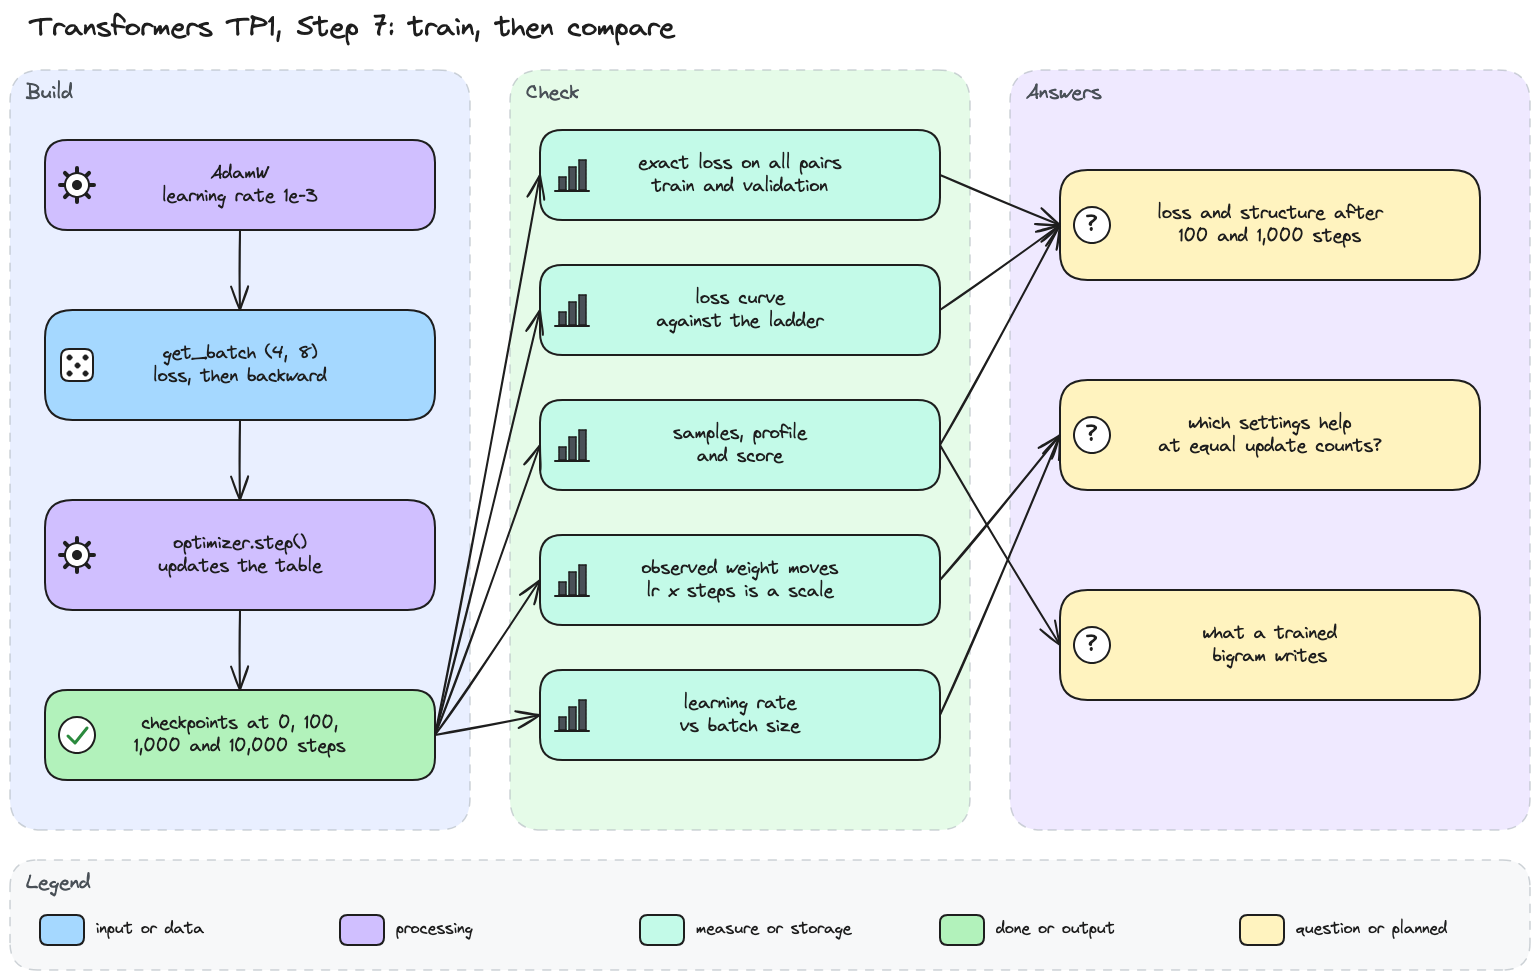

In [51]:
# Step 7 diagram: the training loop, the checkpoints and the experiments behind my answers.
display(Image(filename='diagrams/transformers/tp1_step7.png', width=900))

In [52]:
# Inspect one prediction's gradient on a copied row without updating the model.
demo_grad_row = demo_row.detach().clone().requires_grad_(True)
demo_grad_loss = F.cross_entropy(demo_grad_row[None, :], torch.tensor([demo_target]))
demo_gradient, = torch.autograd.grad(demo_grad_loss, demo_grad_row)
demo_expected = demo_probs.clone()
demo_expected[demo_target] -= 1
print(f"Gradient for target 't': {demo_gradient[demo_target]:.4f}")
print(f"Gradient for alternative 's': {demo_gradient[demo_current]:.4f}")
print(f'Sum of gradients across the row: {demo_gradient.sum():.6f}')
assert torch.allclose(demo_gradient, demo_expected, atol=1e-7)
assert demo_gradient[demo_target] < 0 < demo_gradient[demo_current]
assert torch.equal(demo_row, model.token_embedding_table.weight[demo_current].detach().cpu())
assert all(parameter.grad is None for parameter in model.parameters())

Gradient for target 't': -0.9733
Gradient for alternative 's': 0.0187
Sum of gradients across the row: 0.000000


The gradient for the target `t` is -0.9733, while the alternative `s` has 0.0187. Subtracting this gradient would raise the target score and lower the alternative. For this loss, the gradient is the predicted probability minus the target indicator.

I calculated these derivatives on a detached copy. The assertions check their formula and confirm that the original row and model gradients remain untouched. Calculating a gradient does not itself train the model.

In the training loop, `zero_grad` clears old gradients, `backward` computes new ones, and `step` applies AdamW's update. AdamW uses gradient history and weight decay, so its update is more involved than directly subtracting this single gradient.

I now train the original table. The existing exact-loss calculation weights each possible pair by its count, giving the same average as evaluating every adjacent pair individually.

In [53]:
# Tools: exact loss on a split, a checkpoint of the model, and the training loop with its log.
val_pairs = torch.zeros((vocab_size, vocab_size))
val_pairs.index_put_((val_data[:-1], val_data[1:]), torch.ones(len(val_data) - 1), accumulate=True)


def exact_loss(model: nn.Module, pair_counts: torch.Tensor) -> float:
    """Loss of the bigram table on every pair of a split, from the counts of its pairs."""
    weights = model.token_embedding_table.weight.detach().cpu()
    return (-(pair_counts * F.log_softmax(weights, dim=1)).sum() / pair_counts.sum()).item()


def checkpoint(model: nn.Module, name: str) -> dict:
    """Exact losses and a seeded 2,000-character sample with its score under the train table."""
    cpu_state = torch.get_rng_state()  # sampling must not change the training batches
    torch.manual_seed(RANDOM_STATE)
    context = torch.zeros((1, 1), dtype=torch.long, device=device)
    ids = model.generate(context, max_new_tokens=2000)[0].cpu()
    torch.set_rng_state(cpu_state)
    return {'name': name, 'train': exact_loss(model, train_pairs),
            'val': exact_loss(model, val_pairs), 'sample': decode(ids.tolist()),
            'score': -torch.log(smoothed[ids[:-1], ids[1:]]).mean().item()}


def new_log(model: nn.Module) -> dict:
    """Empty training log that starts with the exact losses of the model as it is."""
    return {'batch': [], 'exact': [(0, exact_loss(model, train_pairs),
                                    exact_loss(model, val_pairs))]}


def train(model: nn.Module, optimizer: torch.optim.Optimizer, steps: int, log: dict) -> float:
    """Train on random train batches, logging batch losses and exact losses every 10 steps."""
    for _ in range(steps):
        xb, yb = get_batch("train")
        logits, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        log['batch'].append(loss.item())
        if len(log['batch']) % 10 == 0:
            log['exact'].append((len(log['batch']), exact_loss(model, train_pairs),
                                 exact_loss(model, val_pairs)))
    return loss.item()

In [54]:
# Train for 100 steps with AdamW, keeping checkpoints before and after.
torch.manual_seed(RANDOM_STATE)  # the same batches at every run
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
start_weights = model.token_embedding_table.weight.detach().cpu().clone()
checkpoints = [checkpoint(model, 'before training')]
log = new_log(model)

last = train(model, optimizer, 100, log)
checkpoints.append(checkpoint(model, 'after 100 steps'))
weights_100 = model.token_embedding_table.weight.detach().cpu().clone()

print(f'Last batch loss: {last:.4f}')
print(f'Same sample as section 6 before training: {checkpoints[0]["sample"] == sample}')
for point in checkpoints:
    print(f'{point["name"]}: train {point["train"]:.2f}, validation {point["val"]:.2f}')

Last batch loss: 4.7385
Same sample as section 6 before training: True
before training: train 4.76, validation 4.76
after 100 steps: train 4.68, validation 4.69


The last batch loss is 4.7385, while the exact training loss after 100 updates is 4.68. This illustrates why I chose an evaluation over all pairs instead of using the last batch as the result.

Training and validation begin near 4.76 and reach 4.68 and 4.69. The decrease of about 0.08 supports my expectation of limited progress after 100 updates in this run.

The starting sample matches section 6. I can now compare the output while keeping the initial context, sampling procedure and seed fixed.

In [55]:
# What does the table write after 100 steps? The same seeded sample, and its score.
print(checkpoints[1]['sample'][:300])
print(f'\nScore under the train table: {checkpoints[1]["score"]:.2f} nats per character '
      f'(before training: {checkpoints[0]["score"]:.2f})')


X;wVzBZxtXtKOY?nMHH$imWClMLKLoiCEavkET'-r$ijdO'Xn'3sdtueXccQHc,qnwdJnUN
o ;
!tZi y$,gzNwH$J
S:wyci3GPM
Dp&ZnERV!,BGOMvs!,iHLi3CYwVmG$AQz&xgJpcxW-m3UXz,BnCgZ&PHLapEZx?Q..:mP?AsYDJKU.'ir:mtQHLXaxgucQDxLMDvTBX!,FA'gHuordVlI;fOMq J&iqjvan'XM,gSVHPTWe'g.jhCY3Z-MZUp-JnYxnK3Lg..ThoJPAOEm:gHcN TJq'JPwuo,Zi

Score under the train table: 7.01 nats per character (before training: 7.04)


The displayed sample changes little, and its transition score moves from 7.04 to 7.01. I see a numerical improvement but no clear improvement in readability.

Using the same seed makes these checkpoint samples easier to compare. It does not represent the range of all possible generations. I continue the same training run to 1,000 updates before drawing a stronger conclusion.

In [56]:
# Continue to 1,000 steps in total, then a new checkpoint.
last = train(model, optimizer, 900, log)
checkpoints.append(checkpoint(model, 'after 1,000 steps'))
weights_1000 = model.token_embedding_table.weight.detach().cpu().clone()

print(f'Last batch loss: {last:.4f}')
for point in checkpoints:
    print(f'{point["name"]}: train {point["train"]:.2f}, validation {point["val"]:.2f}')

Last batch loss: 4.3153
before training: train 4.76, validation 4.76
after 100 steps: train 4.68, validation 4.69
after 1,000 steps: train 4.09, validation 4.11


After 1,000 updates, the exact losses are 4.09 on training and 4.11 on validation. Training loss has fallen by 0.67, which supports my expectation of a clearer decrease.

Yet 4.09 is only slightly below the uniform reference of 4.17 and remains above the whole-corpus frequency reference of 3.31. The decrease is real, but the model still performs poorly on this scale.

The last batch gives 4.3153, again differing from the exact training score. I next inspect the sample to see whether the measured improvement is visible in the text.

In [57]:
# What does the table write after 1,000 steps? The same seeded sample, and its score.
print(checkpoints[2]['sample'][:300])
print(f'\nScore under the train table: {checkpoints[2]["score"]:.2f} nats per character')



OwVzBZxtltKOY?nqHH$imWClMLKLonCEavk?q'-r$ijdO'Xn'3sd.ueXccQHc,qnwdJnUN
o ;
!tZi y$,gzNwH$J
S:wyci3GPM
D: cDERV!,BGOMuM!,iHLimgYwVmG$AQz&xghecxW-maUXz,BnCHvQrDLapEZx?Q..:mP?ARYDJKU.'ir:mtQHLXashucQDxLMDo.yX!,FA'gHuordVlI;fOMq J&ivkJWP:rM,gSVHPTWe'g.jhCY3Z-MZUp-JnYxnK3Lg..ThoJPAOEm:grAsTkJq'JPwuotl'

Score under the train table: 6.59 nats per character


The sample still contains noise, with fragments such as `D: cDERV` and `ghecxW`. Its transition score falls to 6.59, but readable dialogue does not emerge in this extract.

My expectation about a trained bigram is not supported at this checkpoint. It remains possible that training is incomplete. I examine the learning curve before blaming the one-character context alone.

After 1,000 steps, validation minus train: 0.015 nats


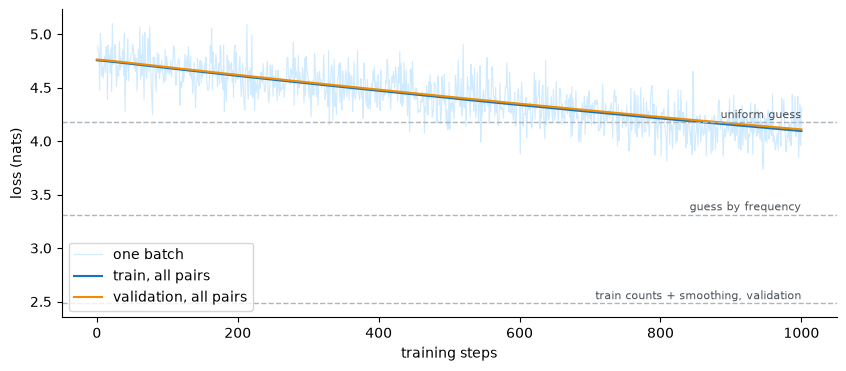

In [58]:
# How did the loss move over the 1,000 steps? Batch losses against the exact losses and my levels.
exact_steps = [step for step, _, _ in log['exact']]
gap = log['exact'][-1][2] - log['exact'][-1][1]
print(f'After {exact_steps[-1]:,} steps, validation minus train: {gap:.3f} nats')

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(1, len(log['batch']) + 1), log['batch'], color='#d0ebff', linewidth=0.8,
        label='one batch')
ax.plot(exact_steps, [loss for _, loss, _ in log['exact']], color='#1971c2',
        label='train, all pairs')
ax.plot(exact_steps, [loss for _, _, loss in log['exact']], color='#f08c00',
        label='validation, all pairs')
for level, name in ((math.log(vocab_size), 'uniform guess'), (entropy, 'guess by frequency'),
                    (val_loss, 'train counts + smoothing, validation')):
    ax.axhline(level, color='#adb5bd', linestyle='--', linewidth=1)
    ax.text(exact_steps[-1], level + 0.04, name, ha='right', fontsize=8, color='#495057')
ax.set_xlabel('training steps')
ax.set_ylabel('loss (nats)')
ax.legend(loc='lower left')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The exact losses keep decreasing through 1,000 updates. Their gap is 0.015 nats, so this checkpoint shows little separation between training and validation.

That observation does not rule out overfitting in general. Both scores remain far above the count-based references, which makes incomplete optimisation a plausible explanation here.

The batch losses fluctuate around the smoother exact curves. I also see no clear plateau yet. This motivates checking weight movement and trying more updates before changing the architecture.

line break: text 3.59%, before training 1.35%, after 100 steps 1.35%, after 1,000 steps 1.85%
space: text 15.23%, before training 1.5%, after 100 steps 1.45%, after 1,000 steps 1.55%
punctuation: text 4.88%, before training 15.19%, after 100 steps 15.09%, after 1,000 steps 14.84%
digit: text 0.0%, before training 1.95%, after 100 steps 1.95%, after 1,000 steps 1.55%
uppercase letter: text 7.96%, before training 40.18%, after 100 steps 40.23%, after 1,000 steps 37.73%
lowercase letter: text 68.35%, before training 39.83%, after 100 steps 39.93%, after 1,000 steps 42.48%


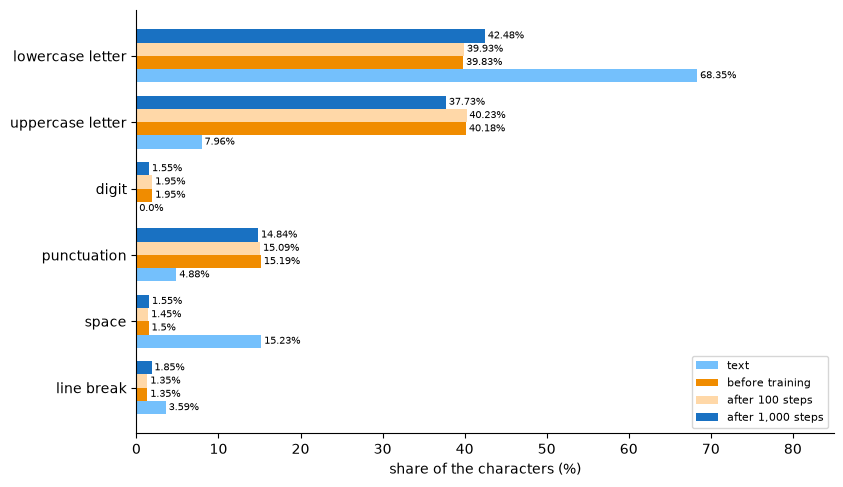

In [59]:
# How does the character profile move? The text against the samples at each checkpoint.
profiles = {'text': {cat: percentage(occurrences[cat], len(text)) for cat in CATEGORY_COLOURS}}
for point in checkpoints:
    found = Counter(character_category(char) for char in point['sample'])
    profiles[point['name']] = {cat: percentage(found[cat], len(point['sample']))
                               for cat in CATEGORY_COLOURS}
for cat in CATEGORY_COLOURS:
    print(f'{cat}: ' + ', '.join(f'{name} {shares[cat]}%' for name, shares in profiles.items()))

rows = torch.arange(len(CATEGORY_COLOURS))
colours = ['#74c0fc', '#f08c00', '#ffd8a8', '#1971c2']
fig, ax = plt.subplots(figsize=(9, 5.5))
for k, ((name, shares), colour) in enumerate(zip(profiles.items(), colours)):
    bars = ax.barh(rows + 0.2 * (k - 1.5), list(shares.values()), height=0.2, color=colour,
                   label=name)
    ax.bar_label(bars, labels=[f'{share}%' for share in shares.values()], padding=2, fontsize=7)
ax.set_yticks(rows, list(CATEGORY_COLOURS))
ax.set_xlim(0, 85)
ax.set_xlabel('share of the characters (%)')
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

After 1,000 updates, capitals fall from 40.18% to 37.73% and lowercase letters rise from 39.83% to 42.48%. These remain far from the corpus shares of 7.96% and 68.35%.

Spaces also remain near 1.5%, compared with 15.23% in the corpus. The direction is encouraging, but the model has not reproduced even this coarse character profile.

I now inspect how much the table has moved. This can suggest why training is slow, although movement alone cannot identify the cause.

In [60]:
# Compare observed weight movement with lr x steps as a scale, not an update bound.
for steps, weights in ((100, weights_100), (1_000, weights_1000)):
    moves = (weights - start_weights).abs()
    print(f'After {steps:,} steps: mean move {moves.mean():.3f}, largest {moves.max():.3f}, '
          f'lr x steps = {1e-3 * steps:.1f}')

# Compare rows by corpus frequency; momentum and decay also affect their movement.
row_moves = (weights_1000 - start_weights).abs().mean(dim=1)
frequent = sorted(range(vocab_size), key=lambda i: counts[itos[i]], reverse=True)
print(f'Mean move of the 10 most frequent rows: {row_moves[frequent[:10]].mean():.3f}, '
      f'of the 10 rarest: {row_moves[frequent[-10:]].mean():.3f}')

# How different are the scores inside a row, now and in the smoothed count table?
spread = lambda table_: (table_.max(dim=1).values - table_.min(dim=1).values).mean()
print(f'Mean spread of a row: after 1,000 steps {spread(weights_1000):.2f}, '
      f'smoothed count table {spread(torch.log(smoothed)):.2f}')

After 100 steps: mean move 0.033, largest 0.098, lr x steps = 0.1
After 1,000 steps: mean move 0.306, largest 0.885, lr x steps = 1.0
Mean move of the 10 most frequent rows: 0.528, of the 10 rarest: 0.057
Mean spread of a row: after 1,000 steps 4.65, smoothed count table 7.19


The largest absolute weight changes are 0.098 after 100 updates and 0.885 after 1,000. The latter mean change is 0.306. I compare these observations with `learning rate × steps` only as a rough scale.

That product is not an upper bound for AdamW. Its updates depend on accumulated gradient statistics and weight decay. A row can keep moving through optimiser state even when it receives no new data gradient in the current batch.

Rows for the 10 most frequent corpus characters move by 0.528 on average, compared with 0.057 for the 10 rarest. Frequent characters receive more direct training signals. This association does not isolate the effects of frequency, momentum and decay.

The mean within-row score range is 4.65, compared with 7.19 in the smoothed count table. A wider range alone would not guarantee better predictions because the correct characters also need the correct scores.

The loss is still decreasing and remains above the reference. I therefore continue to 10,000 updates while keeping the model, batch size and learning rate unchanged.

In [61]:
# Continue to 10,000 steps in total: how close does the table get, and what does it write?
last = train(model, optimizer, 9_000, log)
checkpoints.append(checkpoint(model, 'after 10,000 steps'))
point = checkpoints[-1]

print(f'Last batch loss: {last:.4f}')
print(f'After 10,000 steps: train {point["train"]:.2f}, validation {point["val"]:.2f}, '
      f'sample score {point["score"]:.2f}')
print(point['sample'][:400])

Last batch loss: 2.5295
After 10,000 steps: train 2.54, validation 2.57, sample score 3.00


Owearortyo, thard aim pl, KLone
She w or indva wnj&daueveppam, n, ane in b
Gthile f ndde o plwicibl;MAD: in, Thor tous!cin ime wance
B!&xgheco I:
Unl,Bnt s romapian.

B:
RCAn,
S:
H's.
Whif VFlis y menDotind,
AGHHunghele;f ee thive.
Perely mairie fritingrey'h avQYx'K3LOL, hof ors wir s e amyowactour!
ARWP:
Then ryingee blfunoeatustedghave?
Mathevinghtt m!&Ne trs bet tio e o:
Wnothanry, tirishe fa


After 10,000 updates, training loss reaches 2.54 and validation loss 2.57. Both are about 0.09 above their respective count references. Continuing training therefore accounts for much of the earlier poor performance.

The sample's transition score falls to 3.00. Its extract includes name-like lines such as `B:`, `S:` and `ARWP:`, alongside short words including `She`, `Then` and `in`.

It also contains invented strings such as `thard` and `Owearortyo`. I see more script-like local structure, while the model still has no mechanism for recognising a full name or maintaining sentence meaning.

My sample hypothesis is supported by this later extract, with a condition I had left unspecified, the amount of training. The checkpoint at 1,000 updates was insufficient with these settings.

More updates helped, but this does not explain which training setting matters most. I next compare learning rates and batch sizes from freshly initialised tables.

B = 4, lr = 0.001: validation 4.11 after 1,000 steps
B = 32, lr = 0.001: validation 3.80 after 1,000 steps
B = 4, lr = 0.01: validation 2.63 after 1,000 steps
B = 32, lr = 0.01: validation 2.52 after 1,000 steps


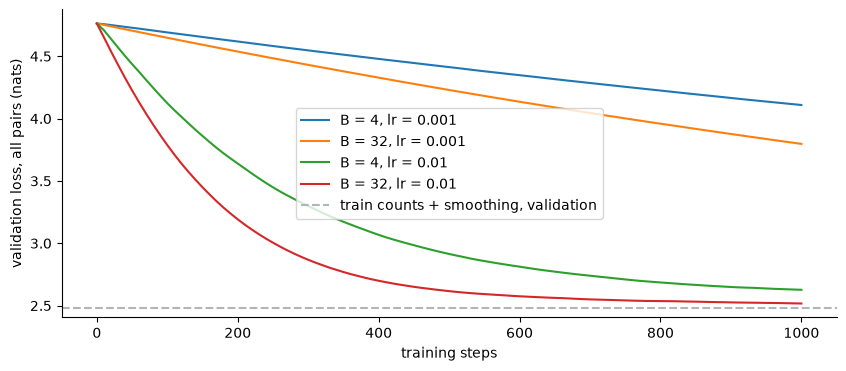

In [62]:
# What limits the table, the batch or the learning rate? Four fresh tables, 1,000 steps each.
SETTINGS = [(4, 1e-3), (32, 1e-3), (4, 1e-2), (32, 1e-2)]
runs = {}
saved_batch_size = batch_size
try:
    for B, lr in SETTINGS:
        batch_size = B  # get_batch reads this global
        torch.manual_seed(RANDOM_STATE)
        fresh = BigramLanguageModel(vocab_size).to(device)
        runs[(B, lr)] = new_log(fresh)
        train(fresh, torch.optim.AdamW(fresh.parameters(), lr=lr), 1_000, runs[(B, lr)])
finally:
    batch_size = saved_batch_size

fig, ax = plt.subplots(figsize=(10, 4))
for (B, lr), run in runs.items():
    print(f'B = {B}, lr = {lr:g}: validation {run["exact"][-1][2]:.2f} after 1,000 steps')
    ax.plot([step for step, _, _ in run['exact']], [loss for _, _, loss in run['exact']],
            label=f'B = {B}, lr = {lr:g}')
ax.axhline(val_loss, color='#adb5bd', linestyle='--', label='train counts + smoothing, validation')
ax.set_xlabel('training steps')
ax.set_ylabel('validation loss, all pairs (nats)')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.show()

At a learning rate of 1e-3, increasing B from 4 to 32 lowers validation loss from 4.11 to 3.80. At 1e-2, the corresponding scores are 2.63 and 2.52 after 1,000 updates.

Within each fixed batch size, the learning-rate change produces the larger improvement among these settings. The runs restart from the same seed and initialisation. This is stronger evidence than inferring a cause from weight movement alone.

The batch comparison has a different budget. B = 32 processes eight times as many predictions per update as B = 4. I can compare performance after equal updates, but cannot claim equal-data or equal-time efficiency.

The larger learning rate reaches the vicinity of the count reference in fewer updates here. I have only one seed and these tested settings, so I cannot conclude that it is generally optimal or always stable.

> *My conclusion:*
>
> With the original settings, training loss falls from 4.76 to 4.68, 4.09 and 2.54 at the successive checkpoints. The later run shows that incomplete training explains much of the poor output after 1,000 updates.
>
> The controlled learning-rate comparison supports that explanation, while the larger-batch runs also change the number of examples processed. I keep these distinctions when interpreting the gains.
>
> The final extract has more plausible local structure and still contains invented words. Approaching a bigram reference does not show that the model understands dialogue.
>
> My answer to the question of this step:
>
> - After 100 updates, the loss barely decreases and the sample remains noise. After 1,000, loss reaches 4.09 but the extract remains unreadable. At 10,000, loss reaches 2.54 and name-like lines and short words appear.

## Summary

I return to my initial expectations and separate what the measurements establish from what remains open. The checkpoint comparison keeps numerical progress and the character of the generated text visible together.

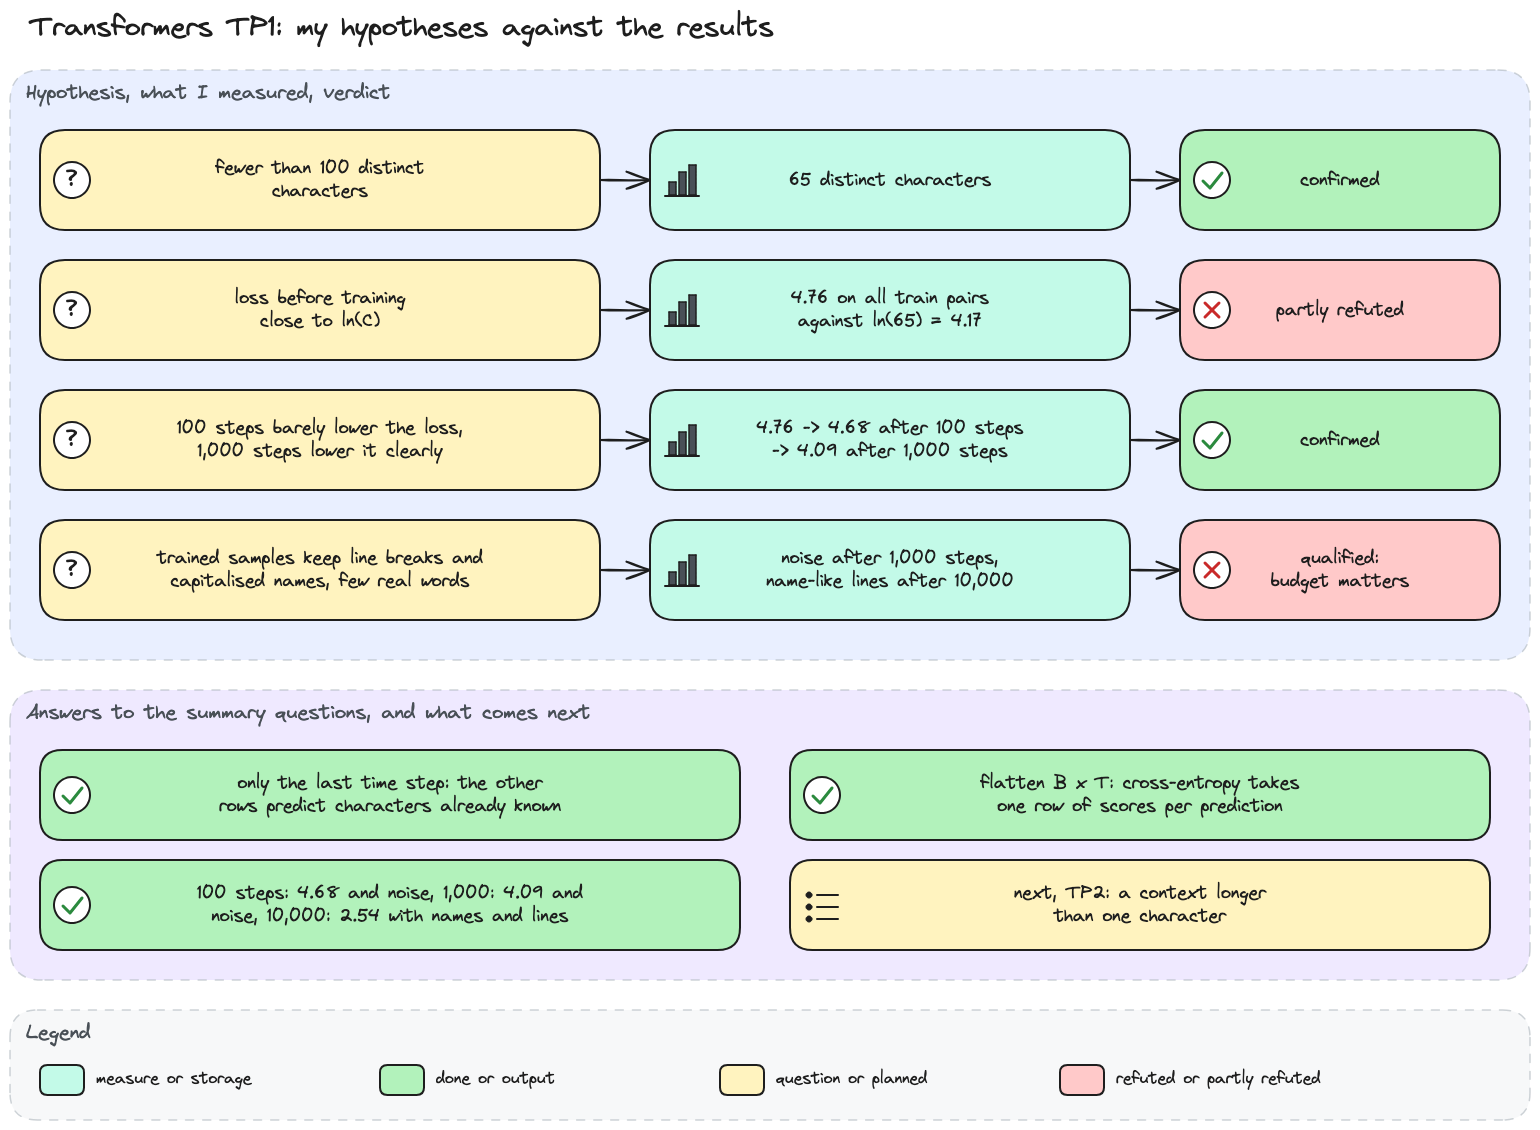

In [63]:
# Summary diagram: my hypotheses, what I measured, my verdicts, and the summary answers.
display(Image(filename='diagrams/transformers/tp1_summary.png', width=900))

before training: train loss 4.76, sample score 7.04
after 100 steps: train loss 4.68, sample score 7.01
after 1,000 steps: train loss 4.09, sample score 6.59
after 10,000 steps: train loss 2.54, sample score 3.00


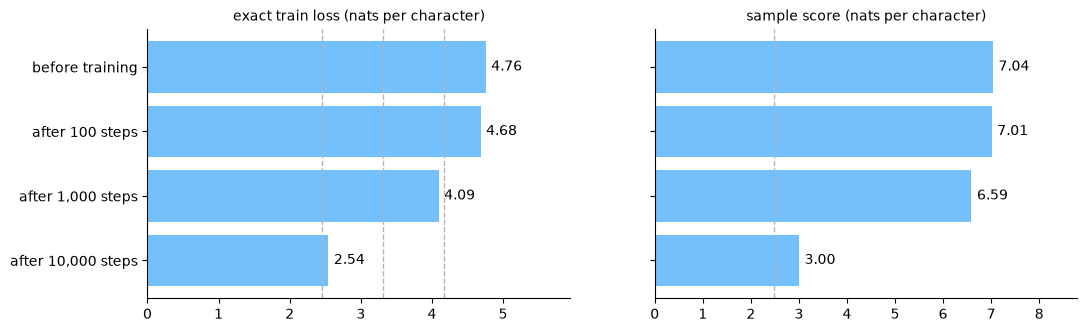

In [64]:
# The whole journey: exact train loss and sample score at each checkpoint, against my levels.
names = [point['name'] for point in checkpoints][::-1]
for point in checkpoints:
    print(f'{point["name"]}: train loss {point["train"]:.2f}, sample score {point["score"]:.2f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, key, title in ((axes[0], 'train', 'exact train loss'), (axes[1], 'score', 'sample score')):
    values = [point[key] for point in checkpoints][::-1]
    bars = ax.barh(names, values, color='#74c0fc')
    ax.bar_label(bars, labels=[f'{value:.2f}' for value in values], padding=4)
    ax.set_xlim(0, max(values) * 1.25)
    ax.set_title(f'{title} (nats per character)', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
for level in (math.log(vocab_size), entropy, train_loss):
    axes[0].axvline(level, color='#adb5bd', linestyle='--', linewidth=1)
axes[1].axvline(val_loss, color='#adb5bd', linestyle='--', linewidth=1)
plt.show()

Exact training loss falls from 4.76 to 4.68, 4.09 and 2.54. The generated samples' transition scores fall from 7.04 to 7.01, 6.59 and 3.00.

Both improve in this run, but they score different things. Training loss evaluates the learned model on fixed text, while the sample score evaluates changing generated text with a fixed count model.

The clearest visible change appears between 1,000 and 10,000 updates. These checkpoints do not locate a universal loss threshold at which readable language begins.

> *My conclusion:*
>
> I built a character predictor with 4,225 learned scores and used counted transitions to judge its progress. My initial hypotheses now have more precise answers.
>
> - The corpus contains 65 distinct characters, which supports my expectation of fewer than 100.
> - Initial loss is 4.76, above ln(C) = 4.17. Random logits do not give uniform probabilities within a row. Equal logits, including all zeros, do.
> - The loss decreases little after 100 updates and more clearly after 1,000, but that decrease is not enough for readable output here.
> - Name-like lines and short words appear in the inspected sample after 10,000 updates. My original statement about a trained sample needed an explicit training budget.
>
> I would now establish reference predictions before interpreting a training loss. The uniform control changed my explanation of initialisation, and exact evaluation prevented a noisy batch from deciding the conclusion.
>
> I would also test an optimisation explanation before changing the architecture. Continuing training and varying the learning rate helped this table approach its reference. A generated extract still needs inspection because plausible pairs can coexist with invented words.
>
> My answers to the three summary questions of TP1:
>
> 1. Generation keeps the last time step because it predicts the next character beyond the current context.
> 2. Flattening B and T presents one score vector and one target per position to cross-entropy, without changing their alignment.
> 3. The samples remain noise at 100 and 1,000 updates despite lower loss. At 10,000, training loss reaches 2.54 and the extract has more script-like structure.
>
> These findings concern one seed, one contiguous split and the inspected samples. Validation has guided the experiments, so it is not an untouched final test.
>
> The remaining architectural question is whether longer context improves predictions such as `First C` followed by `i`. Attention in TP2 introduces a way to use that context. Any gain will still need measurement.